## Probability and Naive Bayes
### What Makes a Song Rap, Rock or EDM? Evidence from 30,000 Spotify Songs

---

### In this notebook

Every song in this dataset has audio features (such as danceability, energy, valence, speechiness, tempo and key) and a **genre** label: pop, rap, rock, latin, r&b or edm. We use these songs to learn the basics of probability, and then build a model that predicts a song's genre.

1. Probability: events, sample space and rules
2. Conditional probability and independence
3. Random variables: discrete vs. continuous
4. Distributions: PMF, PDF, mean and variance
5. Bernoulli, Binomial and Multinomial distributions
6. The Normal distribution (the bell curve)
7. Bayes' theorem: prior, likelihood and posterior
8. From distributions to classifiers: how Naive Bayes works
9. Naive Bayes variants: Gaussian, Bernoulli and Multinomial

**Data Story** sections take a closer look at one surprising result in the data. Each of the nine **Exercise** sections ends with an empty code cell for your work.

*Data: "30,000 Spotify Songs" by Kaylin Pavlik (Spotify Web API), published by [TidyTuesday](https://github.com/rfordatascience/tidytuesday), January 2020.*

### Setup and data loading

Run this cell first. It loads the libraries we need and gives each genre one fixed color, used in every chart.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")

# One fixed color per genre, used in every chart
GENRES = ["pop", "rap", "rock", "latin", "r&b", "edm"]
GENRE_COLORS = {"pop": "#2a78d6", "rap": "#eb6834", "rock": "#1baf7a",
                "latin": "#eda100", "r&b": "#e87ba4", "edm": "#6250d6"}
GRAY = "#c3c2b7"

The data file is stored on GitHub. The link points to one fixed version of the file, so everyone in class loads exactly the same data.

In [2]:
URL = ("https://raw.githubusercontent.com/rfordatascience/tidytuesday/"
       "f422450f6519830f6ce0312e5294e3cf110c72ed/data/2020/2020-01-21/spotify_songs.csv")

raw = pd.read_csv(URL)
print("Rows and columns:", raw.shape)
raw[["track_name", "track_artist", "playlist_genre", "danceability", "energy", "valence", "tempo"]].head()

Rows and columns: (32833, 23)


,track_name,track_artist,playlist_genre,danceability,energy,valence,tempo
0,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,pop,0.748,0.916,0.518,122.036
1,Memories - Dillon Francis Remix,Maroon 5,pop,0.726,0.815,0.693,99.972
2,All the Time - Don Diablo Remix,Zara Larsson,pop,0.675,0.931,0.613,124.008
3,Call You Mine - Keanu Silva Remix,The Chainsmokers,pop,0.718,0.930,0.277,121.956
4,Someone You Loved - Future Humans Remix,Lewis Capaldi,pop,0.650,0.833,0.725,123.976


In [3]:
raw.columns  # inspect original columns before we create `songs`

Index(['track_id', 'track_name', 'track_artist', 'track_popularity',
       'track_album_id', 'track_album_name', 'track_album_release_date',
       'playlist_name', 'playlist_id', 'playlist_genre', 'playlist_subgenre',
       'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
       'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
       'duration_ms'],
      dtype='object')

### The columns we use

| Column | Meaning |
|---|---|
| `playlist_genre` | genre of the playlist the song came from |
| `danceability`, `energy`, `valence` | 0 to 1: how danceable, how intense, how happy |
| `speechiness`, `acousticness` | 0 to 1: how much talking, how acoustic |
| `tempo` | speed in beats per minute (BPM) |
| `key`, `mode` | musical key (0 = C, 1 = C#, ...) and mode (1 = major, 0 = minor) |
| `track_popularity` | Spotify popularity, 0 to 100 |

### Preparing the data

A song can appear in several playlists, so the raw file repeats some tracks. We keep **one row per track** (one row per `track_id`) and add a new column with the song length in minutes.

In [4]:
songs = raw.drop_duplicates("track_id").dropna(subset=["track_name"]).copy()
songs["minutes"] = songs["duration_ms"] / 60_000
print("Rows before:", len(raw), "  Songs after removing repeats:", len(songs))

Rows before: 32833   Songs after removing repeats: 28352


### Data Story 1 Same Song, Different Genre

Many songs are released in several versions (a single, an album track, a remaster), and each version has its own `track_id`. Do all versions of a song get the same genre label?

In [5]:
genres_per_song = songs.groupby(["track_name", "track_artist"])["playlist_genre"].nunique()
print("Songs that carry more than one genre label:", (genres_per_song > 1).sum())

examples = songs[songs["track_name"].isin(["God's Plan", "Smells Like Teen Spirit"])]
examples[["track_name", "track_artist", "track_album_name", "playlist_genre", "danceability", "energy"]]

Songs that carry more than one genre label: 460


,track_name,track_artist,track_album_name,playlist_genre,danceability,energy
2982,God's Plan,Drake,Scorpion,pop,0.754,0.449
3631,Smells Like Teen Spirit,Nirvana,Nirvana (International Version),pop,0.480,0.875
6162,God's Plan,Drake,Scary Hours,rap,0.758,0.448
8992,God's Plan,Drake,Scorpion,rap,0.754,0.449
13700,Smells Like Teen Spirit,Nirvana,Nevermind (Deluxe Edition),rock,0.502,0.912
14571,Smells Like Teen Spirit,Nirvana,Nevermind (Remastered),rock,0.502,0.912


"God's Plan" by Drake is labelled both **pop** and **rap**, and "Smells Like Teen Spirit" by Nirvana is labelled both **pop** and **rock**. The audio numbers of the versions are nearly identical; only the album and the playlist differ. In total, 460 songs carry more than one genre label.

In this dataset, a genre is simply the **label of the playlist** the song was found in, chosen by a person.

**Lesson:** labels made by people are noisy, so no model can be 100% accurate on them. Keep this in mind when we measure accuracy in Section 9.

## 1. Probability: Events, Sample Space and Rules

Probability measures how likely something is, on a scale from 0 (never happens) to 1 (always happens).

| Term | Meaning | Spotify example |
|---|---|---|
| **Experiment** | something with an uncertain result | pick one song at random |
| **Outcome** | one possible result | the song is rock |
| **Sample space** (S) | all possible outcomes | {pop, rap, rock, latin, r&b, edm} |
| **Event** | a group of outcomes we care about | "the song is rap or r&b" |

With data, we estimate a probability as a **share** (a proportion):

$$P(A) \approx \frac{\text{number of times A happened}}{\text{total number of trials}}$$

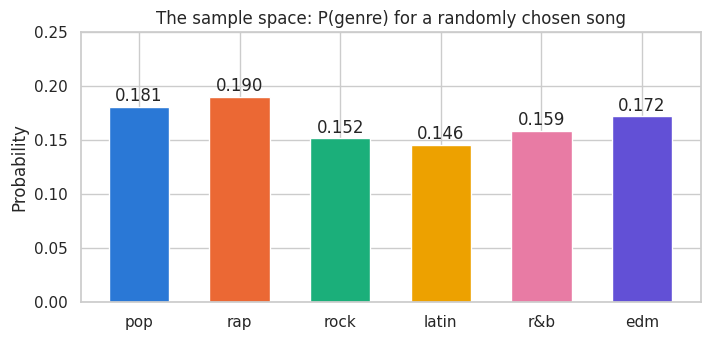

In [6]:
probs = songs["playlist_genre"].value_counts(normalize=True)[GENRES]   # normalize=True gives proportions

plt.figure(figsize=(8, 3.5))
plt.bar(GENRES, probs.values, color=[GENRE_COLORS[g] for g in GENRES], width=0.6)
for i, p in enumerate(probs.values):
    plt.text(i, p + 0.005, f"{p:.3f}", ha="center")
plt.title("The sample space: P(genre) for a randomly chosen song")
plt.ylabel("Probability")
plt.ylim(0, 0.25)
plt.show()

In [7]:
print("The probabilities are:", round(probs, 3))
print("The probabilities add up to:", round(probs.sum(), 3))

The probabilities are: playlist_genre
pop      0.181
rap      0.190
rock     0.152
latin    0.146
r&b      0.159
edm      0.172
Name: proportion, dtype: float64
The probabilities add up to: 1.0


The six genres are roughly equally common (each between about 15% and 19% of songs). Each song belongs to exactly one genre, so the bars add up to 1.

### The basic probability rules

1. **Range**: 0 <= P(A) <= 1.
2. **Total**: the probabilities of all outcomes add up to 1.
3. **Complement**: P(not A) = 1 - P(A).
4. **Addition rule**: P(A or B) = P(A) + P(B) - P(A and B).

**Mutually exclusive** events cannot happen together. Each row in our data has exactly one genre, so a song cannot be both rap and rock. Then P(A and B) = 0, and we simply add.

When events **overlap**, we subtract the overlap so it is not counted twice. Let A = "the song is rap" and B = "the song is very danceable" (danceability 0.8 or more).

In [8]:
A = songs["playlist_genre"] == "rap"
B = songs["danceability"] >= 0.8
p_A, p_B, p_AB = A.mean(), B.mean(), (A & B).mean()     # the mean of True/False is a proportion


print(f"P(A) = {p_A:.3f},  P(B) = {p_B:.3f},  P(A and B) = {p_AB:.3f}")
print(f"Addition rule: P(A or B) = {p_A:.3f} + {p_B:.3f} - {p_AB:.3f} = {p_A + p_B - p_AB:.3f}")
print(f"Counted directly:          {(A | B).mean():.3f}")
print(f"Complement: P(not rap) = 1 - P(rap) = {1 - p_A:.3f}")

P(A) = 0.190,  P(B) = 0.158,  P(A and B) = 0.058
Addition rule: P(A or B) = 0.190 + 0.158 - 0.058 = 0.290
Counted directly:          0.290
Complement: P(not rap) = 1 - P(rap) = 0.810


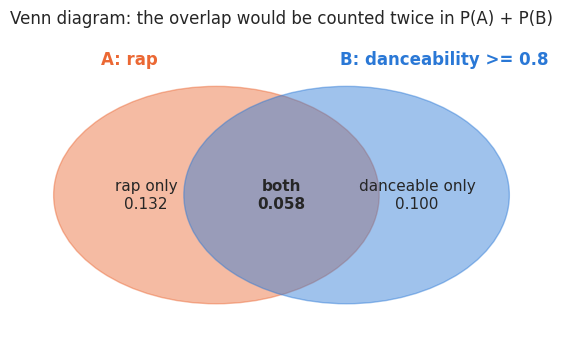

In [9]:
from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(7, 4))
ax.add_patch(Circle((0.38, 0.5), 0.3, color=GENRE_COLORS["rap"], alpha=0.45))
ax.add_patch(Circle((0.62, 0.5), 0.3, color="#2a78d6", alpha=0.45))
ax.text(0.25, 0.5, f"rap only\n{p_A - p_AB:.3f}", ha="center", va="center", fontsize=11)
ax.text(0.50, 0.5, f"both\n{p_AB:.3f}", ha="center", va="center", fontsize=11, weight="bold")
ax.text(0.75, 0.5, f"danceable only\n{p_B - p_AB:.3f}", ha="center", va="center", fontsize=11)
ax.text(0.22, 0.86, "A: rap", ha="center", fontsize=12, color=GENRE_COLORS["rap"], weight="bold")
ax.text(0.80, 0.86, "B: danceability >= 0.8", ha="center", fontsize=12, color="#2a78d6", weight="bold")
ax.set_xlim(0, 1); ax.set_ylim(0.1, 0.95); ax.axis("off")
ax.set_title("Venn diagram: the overlap would be counted twice in P(A) + P(B)")
plt.show()

### Exercise 1 Probability Basics

1. Let C = "the song is rock" and D = "the song is in a major key" (`mode == 1`). Find P(C or D) with the addition rule, then check by counting.
2. Are "rock" and "edm" mutually exclusive? Find P(rock or edm) in two ways.

In [10]:
# Your code here

## 2. Conditional Probability and Independence

If you know a song is very danceable, does your guess about its genre change? We write P(A | B) for "the probability of A **given** B":

$$P(A \mid B) = \frac{P(A \text{ and } B)}{P(B)}$$

In pandas: keep only the rows where B is true, then find the share of those rows where A is also true.

In [11]:
A = songs["playlist_genre"] == "rap"
B = songs["danceability"] >= 0.8
p_A, p_B, p_AB = A.mean(), B.mean(), (A & B).mean()     # the mean of True/False is a proportion

print(f"P(rap)                     = {p_A:.3f}")
print(f"P(rap | very danceable)    = {p_AB / p_B:.3f}   (using formula)")
print(f"P(rap | very danceable)    = {A[B].mean():.3f}   (using filter)")

P(rap)                     = 0.190
P(rap | very danceable)    = 0.367   (using formula)
P(rap | very danceable)    = 0.367   (using filter)


**Visual check:** in the table below, the top row contains only the very danceable songs, which is the group we condition on. Divide the **rap and very danceable** count by the **total of the top row** to get $P(\text{rap} \mid \text{very danceable})$.

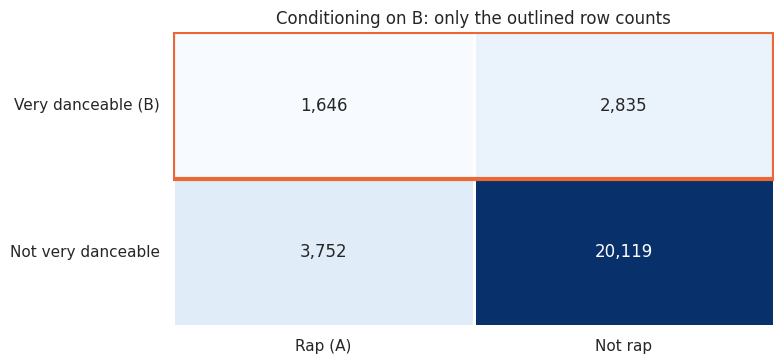

P(rap | very danceable) = 1,646 / 4,481 = 0.367


In [12]:
# Conditional probability: restrict the sample space to the condition B.
contingency = np.array([
    [(A & B).sum(), (~A & B).sum()],
    [(A & ~B).sum(), (~A & ~B).sum()]
], dtype=int)

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.heatmap(contingency, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["Rap (A)", "Not rap"],
            yticklabels=["Very danceable (B)", "Not very danceable"],
            linewidths=2, linecolor="white", ax=ax, annot_kws={"size":12})
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.add_patch(plt.Rectangle((0, 0), 2, 1, fill=False, edgecolor="#eb6834", linewidth=3))
ax.set_title("Conditioning on B: only the outlined row counts")
plt.tight_layout()
plt.show()
print(f"P(rap | very danceable) = {contingency[0,0]:,} / {contingency[0].sum():,}"
      f" = {contingency[0,0] / contingency[0].sum():.3f}")

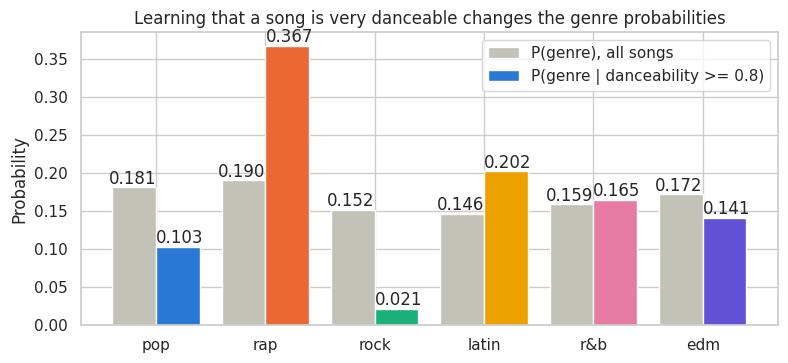

In [13]:
before = probs
after = songs.loc[B, "playlist_genre"].value_counts(normalize=True)[GENRES]
x = np.arange(len(GENRES))
plt.figure(figsize=(9, 3.8))
plt.bar(x - 0.2, before.values, width=0.4, color=GRAY, label="P(genre), all songs")
plt.bar(x + 0.2, after.values, width=0.4, color=[GENRE_COLORS[g] for g in GENRES], label="P(genre | danceability >= 0.8)")
for i, p in enumerate(before.values):
    plt.text(i, p + 0.005, f"{p:.3f}", ha="right")
for i, p in enumerate(after.values):
    plt.text(i, p + 0.005, f"{p:.3f}", ha="left")
plt.xticks(x, GENRES)
plt.title("Learning that a song is very danceable changes the genre probabilities")
plt.ylabel("Probability")
plt.legend()
plt.show()

Among very danceable songs, rap and latin become more likely and rock almost disappears. Knowing the **condition** changes the probabilities.

### Independence

A and B are **independent** if learning B does not change the chance of A:

$$P(A \mid B) = P(A)$$

Since $P(A \mid B) = P(A \text{ and } B)/P(B)$, this is the same as saying (when $P(B) > 0$):

$$P(A \text{ and } B) = P(A) \times P(B)$$

| Form | Meaning |
|---|---|
| $$P(A \mid B)=P(A)$$ | knowing B does not change our belief about A |
| $$P(A \text{ and } B)=P(A)P(B)$$ | the chance of both is the product of the two chances |

### Data Story 2 Rock Is the Major-Key Genre

Songs in a major key tend to sound bright, and songs in a minor key tend to sound darker. Is the mode (major or minor) independent of genre? We first compare $P(\text{major} \mid \text{genre})$ with $P(\text{major})$, and then check the product rule.

In [14]:
major = songs["mode"] == 1
p_major_given_genre = songs.groupby("playlist_genre")["mode"].mean()[GENRES]
print(p_major_given_genre.round(3))

playlist_genre
pop      0.592
rap      0.523
rock     0.693
latin    0.562
r&b      0.522
edm      0.517
Name: mode, dtype: float64


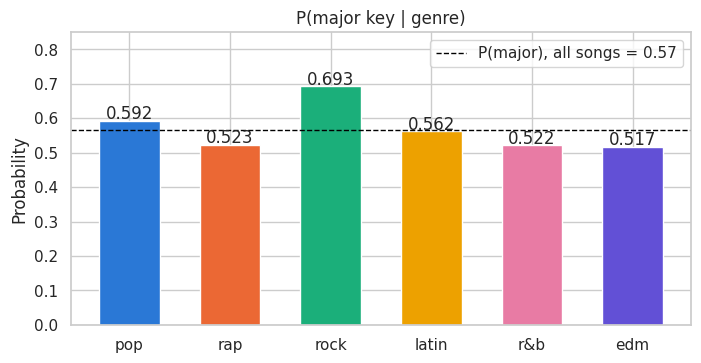

In [15]:
plt.figure(figsize=(8, 3.8))
plt.bar(GENRES, p_major_given_genre.values, color=[GENRE_COLORS[g] for g in GENRES], width=0.6)
for i, p in enumerate(p_major_given_genre.values):
    plt.text(i, p + 0.005, f"{p:.3f}", ha="center")
plt.axhline(major.mean(), color="black", ls="--", lw=1, label=f"P(major), all songs = {major.mean():.2f}")
plt.title("P(major key | genre)")
plt.ylabel("Probability")
plt.ylim(0, 0.85)
plt.legend()
plt.show()

Most genres sit close to the dashed line, which shows $P(\text{major})$ for all songs. **Rock** is the clear exception: about 7 in 10 rock songs (0.69) are in a major key, compared with 0.57 for all songs.

Now check the second form of the rule. For each genre, compare $P(\text{major and genre})$ with $P(\text{major}) \times P(\text{genre})$.

In [16]:
for g in ["pop", "rap", "rock", "latin", "r&b", "edm"]:
    G = songs["playlist_genre"] == g
    print(f"{g:5s}  P(major and {g}) = {(major & G).mean():.4f}   P(major) x P({g}) = {major.mean() * G.mean():.4f}")

pop    P(major and pop) = 0.1072   P(major) x P(pop) = 0.1024
rap    P(major and rap) = 0.0995   P(major) x P(rap) = 0.1077
rock   P(major and rock) = 0.1052   P(major) x P(rock) = 0.0859
latin  P(major and latin) = 0.0819   P(major) x P(latin) = 0.0825
r&b    P(major and r&b) = 0.0829   P(major) x P(r&b) = 0.0898
edm    P(major and edm) = 0.0889   P(major) x P(edm) = 0.0973


The left number is what actually happened. The right number is what we would expect if mode and genre were independent. For latin and pop the two numbers are close, so for these genres mode is nearly independent of genre. For rock they are not: there are about 22% more major-key rock songs than independence predicts (0.105 vs. 0.086).

Both forms of the rule lead to the same conclusion: rock and major key are **not** independent.

### Exercise 2 Conditional Probability

1. Find P(rock | acousticness >= 0.5) and P(edm | acousticness >= 0.5), and compare them with P(rock) and P(edm). Draw a before and after bar chart like the one above.
2. Is "energy >= 0.8" independent of "the song is latin"? Check both forms of the rule.

In [17]:
# Your code here

## 3. Random Variables: Discrete vs. Continuous

A **random variable** assigns a number to each outcome of an experiment.

**Experiment:** make a playlist of three random songs. **Outcome:** the playlist we get. On this one experiment we define two random variables:

- **X** = the number of songs in the key of C
- **T** = the average tempo of the three songs

Each new playlist can give different values of X and T. Random variables come in two types:

- **Discrete** variables take separate, countable values with gaps between them, such as 0, 1, 2 or 3 songs.
- **Continuous** variables are measurements that can take any value in a range, such as tempo.

### X is discrete

Spotify stores musical keys as the numbers 0 to 11 (0 = C, 1 = C#, 2 = D, ...). These numbers are **labels**, not amounts. Below we add readable key names and a 0/1 column that marks whether a song is in C.

In [18]:
KEY_NAMES = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
songs["key_name"] = songs["key"].map(dict(enumerate(KEY_NAMES)))     # 0 -> C, 1 -> C#, ...
songs["in_C"] = (songs["key_name"] == "C").astype(int)                # 1 if the song is in C, else 0

print(songs["key_name"].value_counts())
print(songs["in_C"].value_counts())

key_name
C#    3436
C     3001
G     2907
A     2631
B     2577
D     2478
F     2301
F#    2261
G#    2066
A#    1972
E     1925
D#     797
Name: count, dtype: int64
in_C
0    25351
1     3001
Name: count, dtype: int64


Here are some possible playlists:

| Playlist | Song 1 | Song 2 | Song 3 | X = how many are in C |
|---|---|---|---|---|
| A | F | G | D | 0 |
| B | C | F | F | 1 |
| C | C | C | A | 2 |
| D | C | C | C | 3 |

X is **discrete**: you cannot have 1.5 songs in C. Also, because the key numbers are only labels, an "average key of 5.4" has no meaning.

### T is continuous

An average tempo could be 150.11 BPM, 150.115 BPM, or any value in between. Spotify stores rounded measurements, but the tempo itself is a **continuous** quantity.

Let's sample one playlist and calculate X and T.

In [19]:
playlist = songs.sample(3, random_state=4)               # the outcome: a playlist of 3 random songs
print(playlist[["track_name", "key_name", "in_C", "tempo"]])

print("\nX = how many are in C =", playlist["in_C"].sum())
print("T = average tempo      =", round(playlist["tempo"].mean(), 2), "BPM")

                 track_name key_name  in_C    tempo
4465   Take It All Back 2.0        C     1  148.023
27460           Lone Digger        F     0  123.974
13426    Dengue Woman Blues        F     0  178.320

X = how many are in C = 1
T = average tempo      = 150.11 BPM


**One experiment, two random variables:** the same playlist gives us a discrete *count* (X) and a continuous *average* (T). The diagram below shows how each song feeds into X and T.

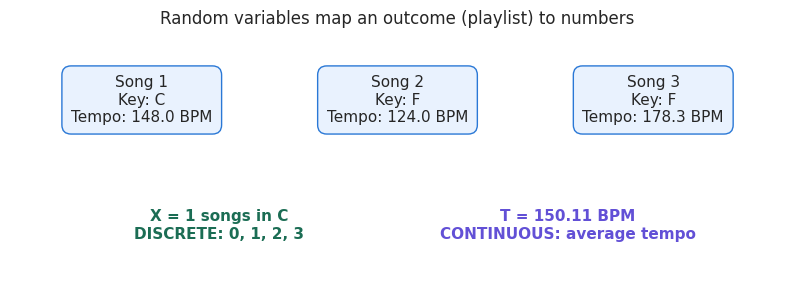

In [20]:
# Visual map: a three-song playlist becomes X and T.
fig, ax = plt.subplots(figsize=(10, 3.1))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
for j, (_, song_row) in enumerate(playlist.iterrows()):
    x_pos = 0.17 + 0.33 * j
    ax.text(x_pos, 0.75, f"Song {j+1}\nKey: {song_row['key_name']}\n"
            f"Tempo: {song_row['tempo']:.1f} BPM", ha="center", va="center", fontsize=11,
            bbox=dict(boxstyle="round,pad=0.6", facecolor="#e9f2fe", edgecolor="#2a78d6"))
ax.annotate("", xy=(0.30, 0.30), xytext=(0.33, 0.56), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.annotate("", xy=(0.70, 0.30), xytext=(0.67, 0.56), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(0.27, 0.17, f"X = {playlist['in_C'].sum()} songs in C\nDISCRETE: 0, 1, 2, 3",
        ha="center", fontsize=11, weight="bold", color="#1b6d54")
ax.text(0.72, 0.17, f"T = {playlist['tempo'].mean():.2f} BPM\nCONTINUOUS: average tempo",
        ha="center", fontsize=11, weight="bold", color="#6250d6")
ax.set_title("Random variables map an outcome (playlist) to numbers", pad=12)
plt.show()

Change `random_state` and you get a new playlist, and so new values of X and T.

| Random variable | Type | Possible values |
|---|---|---|
| X = songs in the key of C in a 3-song playlist | Discrete | 0, 1, 2, 3 |
| N = songs in the key of C in a 10-song playlist | Discrete | 0, 1, ..., 10 |
| T = average tempo of a 3-song playlist | Continuous | any value in a range |

### Exercise 3 Identify Random Variables

1. For each column, say whether it is discrete or continuous, and whether its numbers are real amounts or just labels: `mode`, `track_popularity`, `minutes`, `loudness`, `key`.
2. Make a playlist of 5 random songs. Define one discrete and one continuous random variable on it, and print both values.

<details>
<summary><b>Hint</b></summary>

A number is not always an amount. The `key` column stores 0 to 11, but these are only **labels** for C, C#, D and so on. "The average key is 5.4" means nothing, so treat `key` as a category.

</details>

In [21]:
# Your code here

## 4. Distributions: PMF, PDF, Mean and Variance

One playlist gives one value of X and one value of T. A **distribution** describes all the possible values and how likely each one is.

To estimate the distributions, we repeat the experiment **10,000 times**, making 10,000 random three-song playlists. (This cell takes a few seconds to run.)

In [22]:
X = []   # values of X: how many songs are in C
T = []   # values of T: average tempo

for i in range(10_000):                           # repeat the experiment 10,000 times
    playlist = songs.sample(3, random_state=i)    # one playlist of 3 random songs
    X.append(playlist["in_C"].sum())
    T.append(playlist["tempo"].mean())

X = pd.Series(X)
T = pd.Series(T)
print("First 10 values of X:", X.head(10).tolist())
print("First 5 values of T:", T.head(5).round(2).tolist())

First 10 values of X: [0, 0, 0, 3, 1, 0, 0, 1, 0, 0]
First 5 values of T: [142.69, 118.1, 104.99, 129.59, 150.11]


### PMF: the distribution of a discrete variable

The **probability mass function (PMF)** gives the probability of each possible value, P(X = x). It is drawn as **separate bars**, and the bars **add up to 1**.

Two numbers summarize a distribution:

$$\text{mean } \mu = \sum_x x \, P(X = x) \qquad \text{variance } \sigma^2 = \sum_x (x - \mu)^2 \, P(X = x)$$

- The **mean** (also called the **expected value**) is the balance point of the bars: the long-run average value of X.
- The **variance** is the average squared distance from the mean, so it measures how spread out the values are. Its square root, the **standard deviation (SD)**, is in the same units as X and is roughly the typical distance from the mean.

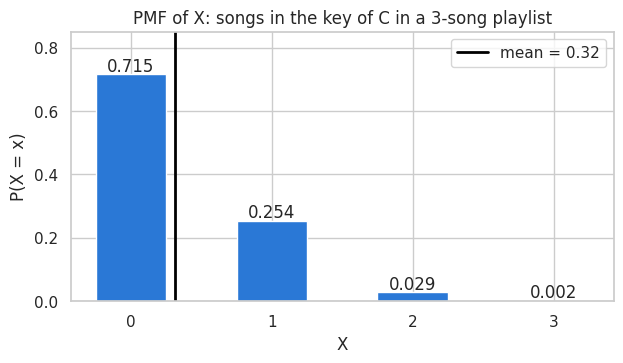

The bars add up to: 1.0
Mean of X from the formula     = 0.32   pandas: 0.32
Variance of X from the formula = 0.28   pandas: 0.28
SD of X = 0.53


In [23]:
pmf = X.value_counts(normalize=True).sort_index()     # estimated P(X = 0), P(X = 1), P(X = 2), P(X = 3)
x, p = pmf.index.to_numpy(), pmf.to_numpy()
mean_X = np.sum(x * p)
var_X = np.sum((x - mean_X) ** 2 * p)

plt.figure(figsize=(7, 3.5))
plt.bar(x, p, color="#2a78d6", width=0.5)
for xi, pi in zip(x, p):
    plt.text(xi, pi + 0.01, f"{pi:.3f}", ha="center")
plt.axvline(mean_X, color="black", lw=2, label=f"mean = {mean_X:.2f}")
plt.title("PMF of X: songs in the key of C in a 3-song playlist")
plt.xlabel("X")
plt.ylabel("P(X = x)")
plt.xticks([0, 1, 2, 3])
plt.ylim(0, 0.85)
plt.legend()
plt.show()

print("The bars add up to:", round(p.sum(), 3))
print(f"Mean of X from the formula     = {mean_X:.2f}   pandas: {X.mean():.2f}")
print(f"Variance of X from the formula = {var_X:.2f}   pandas: {X.var(ddof=0):.2f}")
print(f"SD of X = {np.sqrt(var_X):.2f}")

About 72% of playlists have **no** song in C, and three songs in C almost never happens.

The mean, 0.32, is **not** a value X can take: one playlist always has 0, 1, 2 or 3 songs in C. The mean is the **average over many playlists**, so it can be a decimal even though X is discrete. In Section 5, the Binomial distribution gives a formula for counts like X, so we will not need to simulate.

### PDF: the distribution of a continuous variable

For a continuous variable, a **probability density function (PDF)** shows probability as **area under a curve**:

- The total area under the curve is 1.
- $P(110 \le T < 130)$ is the area between 110 and 130 BPM.
- A single exact value has probability 0, because a single point has no width and so no area.

A histogram with `density=True` scales the bars so that their total **area** is 1. The bar area over a range then estimates the share of playlists in that range.

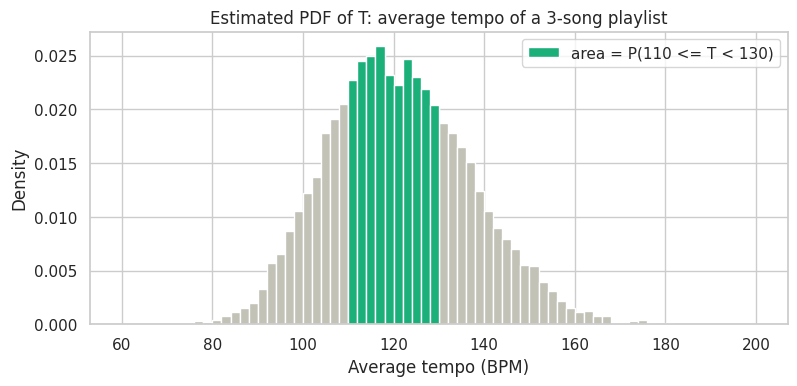

Total area:                       1.000
Shaded area, P(110 <= T < 130):   0.468
Share of playlists in that range: 0.468


In [24]:
bins = np.arange(60, 201, 2)                          # bars 2 BPM wide
heights, edges = np.histogram(T, bins=bins, density=True)
shade = (edges[:-1] >= 110) & (edges[:-1] < 130)

plt.figure(figsize=(9, 3.8))
plt.bar(edges[:-1], heights, width=2, align="edge", color=GRAY, edgecolor="white")
plt.bar(edges[:-1][shade], heights[shade], width=2, align="edge", color="#1baf7a", edgecolor="white",
        label="area = P(110 <= T < 130)")
plt.title("Estimated PDF of T: average tempo of a 3-song playlist")
plt.xlabel("Average tempo (BPM)")
plt.ylabel("Density")
plt.legend()
plt.show()

print(f"Total area:                       {np.sum(heights * 2):.3f}")
print(f"Shaded area, P(110 <= T < 130):   {np.sum(heights[shade] * 2):.3f}")
print(f"Share of playlists in that range: {((T >= 110) & (T < 130)).mean():.3f}")

The shaded area matches the share of playlists in that range. For continuous variables, **probability is area**, not height.

| | Discrete (X) | Continuous (T) |
|---|---|---|
| Distribution | PMF | PDF |
| Picture | separate bars | density curve or histogram |
| Probability | bar height for one value | area over a range |
| One exact value | can have positive probability | probability is 0 |
| Adds up to 1 | sum of bar heights | area under the curve |

### Data Story 3 The Songs Nobody Plays

`track_popularity` is a whole number from 0 to 100, so it is discrete and has a PMF. Let's plot the PMF and mark the mean and one SD on each side of it.

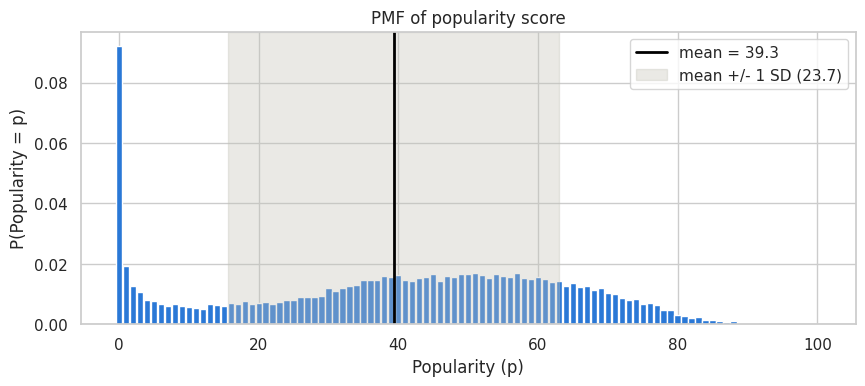

Mean from the PMF formula = 39.34   pandas mean = 39.34
SD from the PMF formula   = 23.70   pandas std (ddof=0) = 23.70
P(Popularity = 0)         = 0.092


In [25]:
pmf = songs["track_popularity"].value_counts(normalize=True).sort_index()
x, p = pmf.index.to_numpy(), pmf.to_numpy()
mean_P = np.sum(x * p)
sd_P = np.sqrt(np.sum((x - mean_P) ** 2 * p))

plt.figure(figsize=(10, 3.8))
plt.bar(x, p, color="#2a78d6", width=0.9)
plt.axvline(mean_P, color="black", lw=2, label=f"mean = {mean_P:.1f}")
plt.axvspan(mean_P - sd_P, mean_P + sd_P, color=GRAY, alpha=0.35, label=f"mean +/- 1 SD ({sd_P:.1f})")
plt.title("PMF of popularity score")
plt.xlabel("Popularity (p)")
plt.ylabel("P(Popularity = p)")
plt.legend()
plt.show()

print(f"Mean from the PMF formula = {mean_P:.2f}   pandas mean = {songs['track_popularity'].mean():.2f}")
print(f"SD from the PMF formula   = {sd_P:.2f}   pandas std (ddof=0) = {songs['track_popularity'].std(ddof=0):.2f}")
print(f"P(Popularity = 0)         = {pmf[0]:.3f}")

The PMF is a broad hump with one odd spike: about **9%** of songs have a popularity of exactly **0**. One possible reason connects to Data Story 1: when a song has several versions, listeners stream one version and the others get almost no plays. This is a hypothesis to investigate, not a proven fact.

**Lesson:** a spike at a single round value (such as 0) is often a sign of something worth investigating.

### Exercise 4 Distributions

1. Plot the PMF of popularity for **rock** songs only. Find its mean and SD with the formulas, then check with pandas.
2. With a density histogram, estimate P(0.4 <= energy <= 0.6) as a shaded area, then check by counting.

<details>
<summary><b>Hint</b></summary>

For part 1, filter first: `rock = songs[songs["playlist_genre"] == "rock"]`. For part 2, copy the PDF of T cell and change `T` to `songs["energy"]`, the bins to `np.linspace(0, 1, 41)`, and the shaded range to 0.4 to 0.6.

</details>

In [26]:
# Your code here

## 5. Bernoulli, Binomial and Multinomial

These three distributions all **count** things.

| Distribution | Situation | Mean | Variance |
|---|---|---|---|
| **Bernoulli** | one trial: 1 (yes) or 0 (no) | $p$ | $p(1 - p)$ |
| **Binomial** | number of yeses in $n$ trials | $np$ | $np(1 - p)$ |
| **Multinomial** | count of each of $k$ outcomes in $n$ trials | $np_i$ for outcome $i$ | $np_i(1 - p_i)$ for outcome $i$ |

### Bernoulli: is one song in a major key?

Pick one random song. Let X = 1 if it is in a major key, and X = 0 if not.

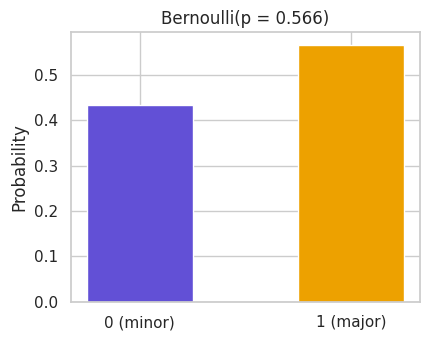

Mean = 0.566 (formula p),  Variance = 0.246 (formula p(1 - p))


In [27]:
p_major = major.mean()
bern = stats.bernoulli(p_major)

plt.figure(figsize=(4.5, 3.5))
plt.bar(["0 (minor)", "1 (major)"], [1 - p_major, p_major], color=["#6250d6", "#eda100"], width=0.5)
plt.title(f"Bernoulli(p = {p_major:.3f})")
plt.ylabel("Probability")
plt.show()

print(f"Mean = {bern.mean():.3f} (formula p),  Variance = {bern.var():.3f} (formula p(1 - p))")

### Binomial: major-key songs in a 10-song playlist

Pick 10 random songs. If each one is major with probability p, **independently** of the others, then the number of major-key songs N follows a **Binomial(n = 10, p)** distribution:

$$P(N = k) = \binom{n}{k} p^k (1 - p)^{n - k}$$

$\binom{n}{k}$ ("n choose k") counts the ways to choose which k of the n songs are major. We check the formula against 10,000 random playlists of real songs.

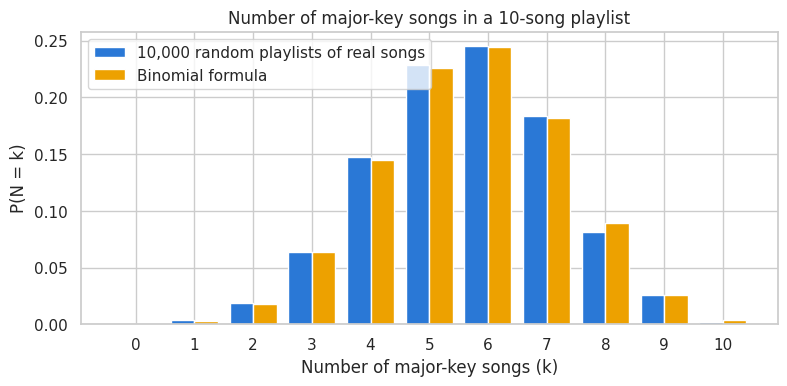

P(N >= 8) from the formula = 0.118   (cdf(7) is P(N <= 7))
P(N >= 8) from simulation  = 0.109


In [28]:
n = 10
k = np.arange(n + 1)
binom_pmf = stats.binom.pmf(k, n, p_major)

rng = np.random.default_rng(42)
playlists = rng.choice(songs["mode"].to_numpy(), size=(10_000, n))     # 10,000 random playlists of real songs
simulated = np.bincount(playlists.sum(axis=1), minlength=n + 1) / 10_000

plt.figure(figsize=(9, 3.8))
plt.bar(k - 0.2, simulated, width=0.4, color="#2a78d6", label="10,000 random playlists of real songs")
plt.bar(k + 0.2, binom_pmf, width=0.4, color="#eda100", label="Binomial formula")
plt.xticks(k)
plt.title("Number of major-key songs in a 10-song playlist")
plt.xlabel("Number of major-key songs (k)")
plt.ylabel("P(N = k)")
plt.legend()
plt.show()

print(f"P(N >= 8) from the formula = {1 - stats.binom.cdf(7, n, p_major):.3f}   (cdf(7) is P(N <= 7))")
print(f"P(N >= 8) from simulation  = {(playlists.sum(axis=1) >= 8).mean():.3f}")

The simulation and the formula agree. Once we trust the formula, it answers questions instantly, with no simulation needed.

### Multinomial: genres in a 12-song shuffle

The Binomial counts two outcomes (yes or no). The **Multinomial** counts several outcomes at once. Shuffle 12 random songs: what is the chance of getting exactly 2 songs from each of the six genres?

P(exactly 2 songs of each genre) = 0.0033


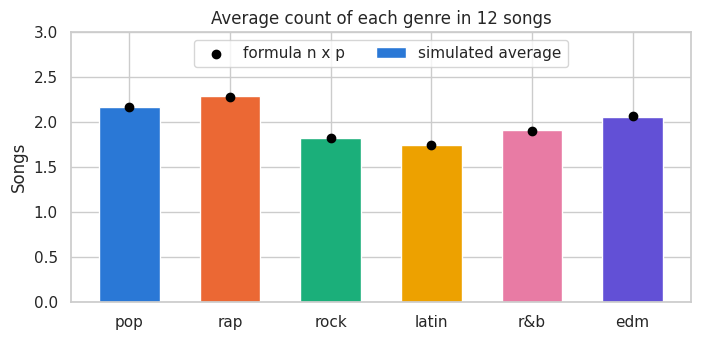

Share of simulated shuffles with exactly 2 of each genre = 0.0028


In [29]:
genre_p = probs.to_numpy()
multi = stats.multinomial(n=12, p=genre_p)
print(f"P(exactly 2 songs of each genre) = {multi.pmf([2, 2, 2, 2, 2, 2]):.4f}")

shuffles = rng.multinomial(12, genre_p, size=10_000)             # 10,000 simulated shuffles
plt.figure(figsize=(8, 3.5))
plt.bar(GENRES, shuffles.mean(axis=0), color=[GENRE_COLORS[g] for g in GENRES], width=0.6, label="simulated average")
plt.scatter(GENRES, 12 * genre_p, color="black", zorder=3, label="formula n x p")
plt.title("Average count of each genre in 12 songs")
plt.ylabel("Songs")
plt.ylim(0, 3)
plt.legend(ncol=2, loc="upper center")
plt.show()

balanced = (shuffles == 2).all(axis=1).mean()
print(f"Share of simulated shuffles with exactly 2 of each genre = {balanced:.4f}")

**One shuffle vs. many shuffles:** the bar chart above shows the *average* count over 10,000 shuffles, which is close to 2 per genre. A single 12-song shuffle can still look very unbalanced, as the chart below shows.

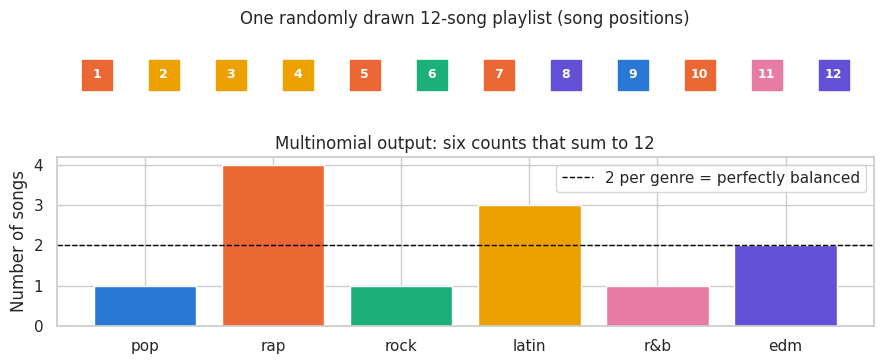

In [30]:
# Visualise one shuffle, not just the average of 10,000 shuffles.
one_shuffle = rng.choice(GENRES, size=12, p=genre_p)
fig, axes = plt.subplots(2, 1, figsize=(9, 3.8), gridspec_kw={"height_ratios": [1, 2]})
for j, g in enumerate(one_shuffle):
    axes[0].scatter(j, 0, marker="s", s=450, color=GENRE_COLORS[g])
    axes[0].text(j, 0, str(j + 1), color="white", ha="center", va="center", weight="bold", fontsize=9)
axes[0].set(xlim=(-0.6, 11.6), ylim=(-0.6, 0.6), title="One randomly drawn 12-song playlist (song positions)")
axes[0].axis("off")
one_counts = pd.Series(one_shuffle).value_counts().reindex(GENRES, fill_value=0)
axes[1].bar(GENRES, one_counts.values, color=[GENRE_COLORS[g] for g in GENRES])
axes[1].axhline(2, color="black", ls="--", lw=1, label="2 per genre = perfectly balanced")
axes[1].set(ylabel="Number of songs", title="Multinomial output: six counts that sum to 12")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

Only about 3 in 1,000 shuffles are perfectly balanced (0.0033 from the formula), even though the genres are about equally common. Random shuffles are lumpy.

### Exercise 5 Shuffle Math

1. A 20-song playlist is built from random **rock** songs. Using P(major | rock) from Section 2, what is the chance that at least 15 are in a major key? Use `stats.binom`.
2. Simulate 10,000 such playlists with `rng.binomial` and check your answer.

In [31]:
# Your code here

## 6. The Normal Distribution: the Bell Curve

The **Normal** (or Gaussian) distribution is the **bell curve**: symmetric, with most values near the middle. It is described by just two numbers: the mean $\mu$ (the center) and the standard deviation $\sigma$ (the width).

Does it fit **valence**, the "happiness" of a song?

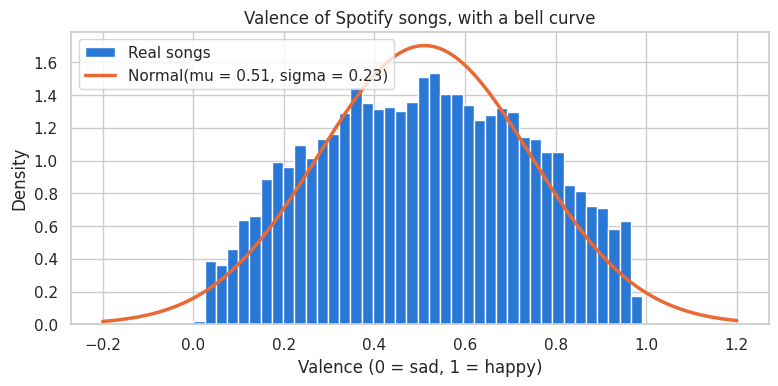

In [32]:
valence = songs["valence"]
mu, sigma = valence.mean(), valence.std()
grid = np.linspace(-0.2, 1.2, 400)

plt.figure(figsize=(9, 3.8))
plt.hist(valence, bins=40, density=True, color="#2a78d6", edgecolor="white", label="Real songs")
plt.plot(grid, stats.norm.pdf(grid, mu, sigma), color="#eb6834", lw=2.5, label=f"Normal(mu = {mu:.2f}, sigma = {sigma:.2f})")
plt.title("Valence of Spotify songs, with a bell curve")
plt.xlabel("Valence (0 = sad, 1 = happy)")
plt.ylabel("Density")
plt.legend()
plt.show()

The bell curve follows the overall shape. Valence cannot go below 0 or above 1, so the real data is a little flatter than the bell, but the bell is still a fair description.

### The 68-95-99.7 rule

For any normal distribution, about **68%** of values fall within 1 SD of the mean, about **95%** within 2 SD and about **99.7%** within 3 SD. The table under the chart compares these numbers with the real valence data.

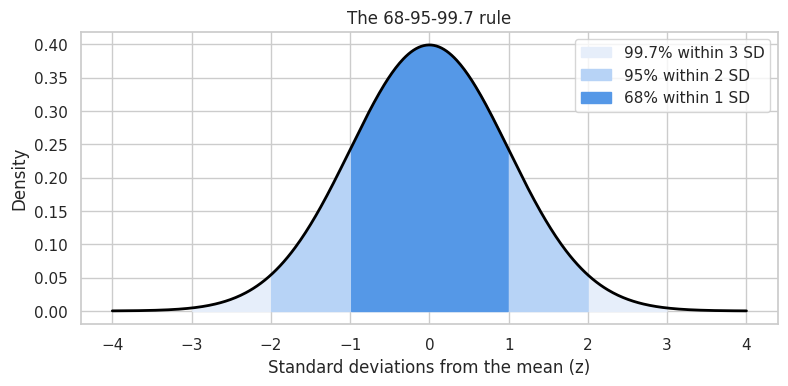

,within,normal rule,real valence
0,1 SD,0.683,0.620
1,2 SD,0.954,0.992
2,3 SD,0.997,1.000


In [33]:
z_grid = np.linspace(-4, 4, 500)
plt.figure(figsize=(9, 3.8))
plt.plot(z_grid, stats.norm.pdf(z_grid), color="black", lw=2)
for k_sd, color, label in [(3, "#e6eefa", "99.7% within 3 SD"), (2, "#b7d3f6", "95% within 2 SD"), (1, "#5598e7", "68% within 1 SD")]:
    mask = np.abs(z_grid) <= k_sd
    plt.fill_between(z_grid[mask], stats.norm.pdf(z_grid[mask]), color=color, label=label)
plt.title("The 68-95-99.7 rule")
plt.xlabel("Standard deviations from the mean (z)")
plt.ylabel("Density")
plt.legend()
plt.show()

rows = [{"within": f"{k} SD", "normal rule": e, "real valence": round((np.abs(valence - mu) <= k * sigma).mean(), 3)}
        for k, e in [(1, 0.683), (2, 0.954), (3, 0.997)]]
pd.DataFrame(rows)

Valence has fewer songs within 1 SD than the rule predicts (62% instead of 68%), because it is flatter than a perfect bell. The rule is a rough but useful guide.

### z-scores: how unusual is a value?

A **z-score** counts how many SDs a value is from the mean:

$$z = \frac{x - \mu}{\sigma}$$

`stats.norm.sf(x, mu, sigma)` gives P(X > x), the area of the right tail ("sf" stands for survival function). How rare is a song with valence above 0.9?

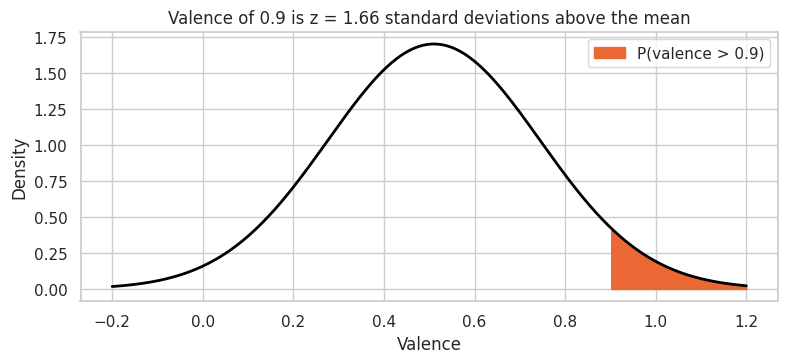

P(valence > 0.9), normal model: 0.048
P(valence > 0.9), real songs:   0.045


In [34]:
z = (0.9 - mu) / sigma
tail = grid >= 0.9

plt.figure(figsize=(9, 3.5))
plt.plot(grid, stats.norm.pdf(grid, mu, sigma), color="black", lw=2)
plt.fill_between(grid[tail], stats.norm.pdf(grid[tail], mu, sigma), color="#eb6834", label="P(valence > 0.9)")
plt.title(f"Valence of 0.9 is z = {z:.2f} standard deviations above the mean")
plt.xlabel("Valence")
plt.ylabel("Density")
plt.legend()
plt.show()

print(f"P(valence > 0.9), normal model: {stats.norm.sf(0.9, mu, sigma):.3f}")
print(f"P(valence > 0.9), real songs:   {(valence > 0.9).mean():.3f}")

### Data Story 4 Not Every Variable Is a Bell Curve

What happens if we fit a bell curve to song **length** in minutes?

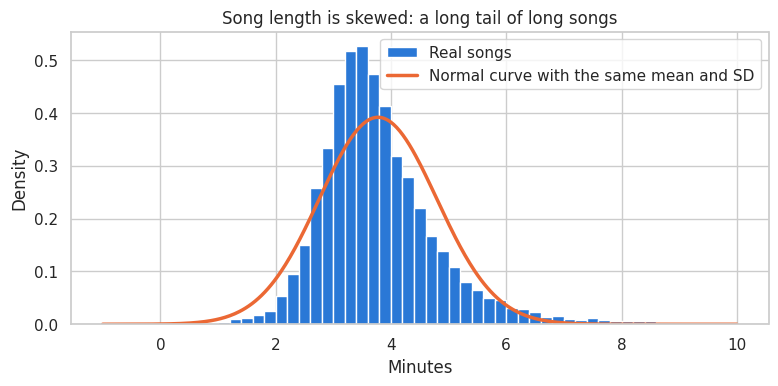

Skewness: 1.12   (0 means symmetric)
Longest song: 8.6 minutes, a z-score of 4.8


In [35]:
minutes = songs["minutes"]
m_mu, m_sigma = minutes.mean(), minutes.std()
grid_m = np.linspace(-1, 10, 400)

plt.figure(figsize=(9, 3.8))
plt.hist(minutes, bins=np.arange(0, 10.1, 0.2), density=True, color="#2a78d6", edgecolor="white", label="Real songs")
plt.plot(grid_m, stats.norm.pdf(grid_m, m_mu, m_sigma), color="#eb6834", lw=2.5, label="Normal curve with the same mean and SD")
plt.title("Song length is skewed: a long tail of long songs")
plt.xlabel("Minutes")
plt.ylabel("Density")
plt.legend()
plt.show()

print(f"Skewness: {stats.skew(minutes):.2f}   (0 means symmetric)")
print(f"Longest song: {minutes.max():.1f} minutes, a z-score of {(minutes.max() - m_mu) / m_sigma:.1f}")

Most songs last 3 to 4 minutes, but a few last 8 minutes or more. The data is **skewed right**: it has a long tail on the right (skewness 1.12). The bell curve is too low at the peak, and it treats the longest song (a z-score of 4.8) as almost impossible.

**Lesson:** always plot the data before assuming a bell curve. This matters later: Gaussian Naive Bayes (Section 9) assumes that each feature has a bell shape within each genre.

### Exercise 6 Your Own Bell Curve

1. Fit a normal curve to the **danceability** of **rap** songs. Plot the histogram with the curve on top and check the 68-95-99.7 rule.
2. What is the z-score of a rap song with danceability 0.95? Estimate P(danceability > 0.95) for rap with the model and compare with the real share.

In [36]:
# Your code here

## 7. Bayes' Theorem: Prior, Likelihood and Posterior

In Section 2 we computed a **conditional probability**: the chance of a genre *given* something we know about a song. Bayes' theorem tells us how to **update** a probability when we learn new evidence.

It helps to think in three steps:

1. **Prior:** what did we believe *before* seeing the evidence?
2. **Likelihood:** how likely is this evidence *if* the hypothesis is true?
3. **Posterior:** what should we believe *after* seeing the evidence?

Bayes' theorem connects them:

$$P(A \mid B) = \frac{P(B \mid A) \times P(A)}{P(B)}$$

| Term | Symbol | Meaning |
|---|---|---|
| **Prior** | $P(A)$ | probability of the hypothesis **before** the evidence |
| **Likelihood** | $$P(B \mid A)$$ | how likely the evidence is **if** the hypothesis is true |
| **Evidence** | $P(B)$ | how common the evidence is across **all** songs |
| **Posterior** | $$P(A \mid B)$$ | updated probability of the hypothesis **given** the evidence |

In words: **posterior = likelihood x prior / evidence**.

**Be careful:** $P(A \mid B)$ and $P(B \mid A)$ are **not** the same thing. Bayes' theorem is how we get from one to the other.

### Connecting Bayes to Section 2

Let the hypothesis be **"the song is rap"** and the evidence be **"danceability >= 0.8"**.

- **Prior:** $P(\text{rap})$, the share of *all songs* labelled rap.
- **Likelihood:** $P(\text{danceability} \geq 0.8 \mid \text{rap})$, the share of *rap songs* that are very danceable.
- **Evidence:** $P(\text{danceability} \geq 0.8)$, the share of *all songs* that are very danceable.
- **Posterior:** $P(\text{rap} \mid \text{danceability} \geq 0.8)$, the share of *very danceable songs* labelled rap.

$$P(\text{rap} \mid \text{danceability}\geq0.8)
= \frac{P(\text{danceability}\geq0.8 \mid \text{rap})\,P(\text{rap})}{P(\text{danceability}\geq0.8)}
\approx 0.367$$

So **about 36.7% of very danceable songs are rap**. This is the same number we counted directly in Section 2, now read as an updated belief: the prior was 0.190, and the evidence raised it to 0.367. It does **not** mean that 36.7% of rap songs are very danceable; that would reverse the condition.

**Looking ahead:** the distributions in Sections 5 and 6 describe how likely an observation is within a group, which is exactly what a likelihood is. In Sections 8 and 9, Naive Bayes combines the likelihoods of several audio features to classify songs.

### Data Story 5 The Base Rate Trap

A friend says: "A song with extremely high energy (above 0.9) is probably EDM." Is that right? We compute the prior, likelihood, evidence and posterior to find out.

Prior,      P(edm)                = 0.172
Likelihood, P(high energy | edm)  = 0.306   (compare: 0.136 for all songs)
Evidence,   P(high energy)        = 0.136
Posterior,  P(edm | high energy)  = 0.387


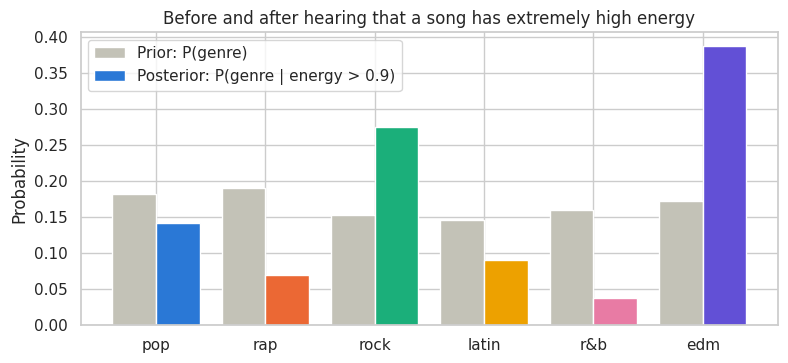

In [37]:
edm = songs["playlist_genre"] == "edm"
high_energy = songs["energy"] > 0.9

prior = edm.mean()
likelihood = high_energy[edm].mean()
evidence = high_energy.mean()
posterior = likelihood * prior / evidence

print(f"Prior,      P(edm)                = {prior:.3f}")
print(f"Likelihood, P(high energy | edm)  = {likelihood:.3f}   (compare: {evidence:.3f} for all songs)")
print(f"Evidence,   P(high energy)        = {evidence:.3f}")
print(f"Posterior,  P(edm | high energy)  = {posterior:.3f}")

after = songs.loc[high_energy, "playlist_genre"].value_counts(normalize=True)[GENRES]
x = np.arange(len(GENRES))
plt.figure(figsize=(9, 3.8))
plt.bar(x - 0.2, probs.values, width=0.4, color=GRAY, label="Prior: P(genre)")
plt.bar(x + 0.2, after.values, width=0.4, color=[GENRE_COLORS[g] for g in GENRES], label="Posterior: P(genre | energy > 0.9)")
plt.xticks(x, GENRES)
plt.title("Before and after hearing that a song has extremely high energy")
plt.ylabel("Probability")
plt.legend()
plt.show()

**Why the prior matters:** the table below shows the four groups behind the calculation. Among high-energy songs, compare the number of EDM songs with the total number of high-energy songs.

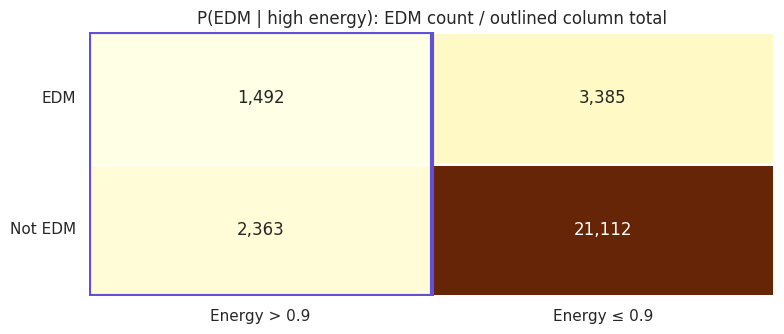

P(EDM | high energy) = 1,492 / 3,855 = 0.387


In [38]:
# Frequency view of Bayes' theorem: all four cells of the same population.
groups = np.array([
    [(edm & high_energy).sum(), (edm & ~high_energy).sum()],
    [(~edm & high_energy).sum(), (~edm & ~high_energy).sum()]
], dtype=int)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(groups, annot=True, fmt=",d", cmap="YlOrBr", cbar=False,
            xticklabels=["Energy > 0.9", "Energy ≤ 0.9"],
            yticklabels=["EDM", "Not EDM"], linewidths=2, linecolor="white", ax=ax)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.add_patch(plt.Rectangle((0, 0), 1, 2, fill=False, edgecolor="#6250d6", linewidth=3))
ax.set_title("P(EDM | high energy): EDM count / outlined column total")
plt.tight_layout()
plt.show()
print(f"P(EDM | high energy) = {groups[0,0]:,} / {groups[:,0].sum():,} = {posterior:.3f}")

Very high energy makes EDM more likely (from 0.172 up to 0.387), but EDM is still **below 40%**, so the friend is wrong: most very high-energy songs are not EDM, because other genres (especially rock) can also be very energetic. Forgetting how common a class was **before** seeing the evidence is called the **base rate fallacy**.

### Updating across all six genres

Now let the evidence be **high speechiness** (speechiness above 0.3, meaning lots of spoken words). For each genre, we multiply prior x likelihood, then divide by the total so that the six posteriors add up to 1.

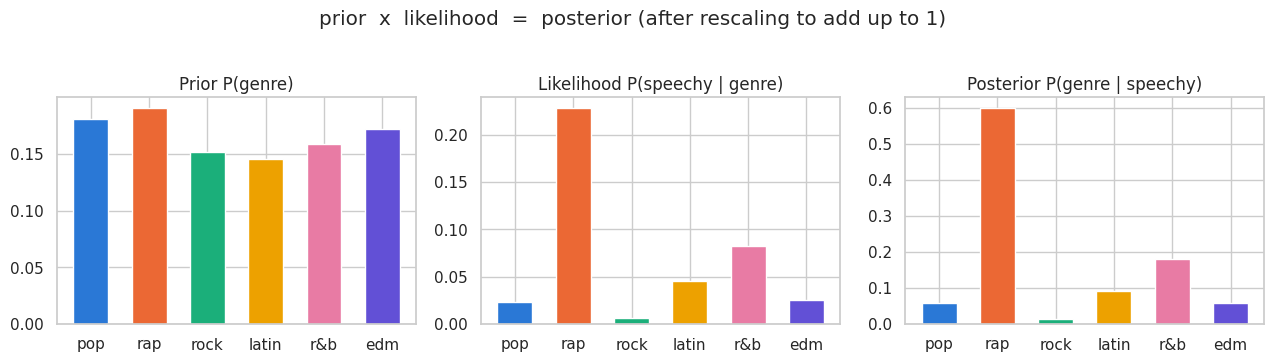

,prior,likelihood P(speechy | genre),prior x likelihood,posterior
pop,0.181,0.023,0.004,0.058
rap,0.190,0.228,0.043,0.598
rock,0.152,0.007,0.001,0.014
latin,0.146,0.045,0.007,0.091
r&b,0.159,0.082,0.013,0.180
edm,0.172,0.025,0.004,0.059


In [39]:
speechy = songs["speechiness"] > 0.3
table = pd.DataFrame({"prior": probs,
                      "likelihood P(speechy | genre)": [speechy[songs["playlist_genre"] == g].mean() for g in GENRES]},
                     index=GENRES)
table["prior x likelihood"] = table["prior"] * table["likelihood P(speechy | genre)"]
table["posterior"] = table["prior x likelihood"] / table["prior x likelihood"].sum()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=False)
for ax, col, title in zip(axes, ["prior", "likelihood P(speechy | genre)", "posterior"],
                          ["Prior P(genre)", "Likelihood P(speechy | genre)", "Posterior P(genre | speechy)"]):
    ax.bar(GENRES, table[col], color=[GENRE_COLORS[g] for g in GENRES], width=0.6)
    ax.set(title=title)
plt.suptitle("prior  x  likelihood  =  posterior (after rescaling to add up to 1)", y=1.03)
plt.tight_layout()
plt.show()

table.round(3)

The prior is nearly flat, but the likelihood is much taller for rap, so rap gets the highest posterior (about 0.60).

Notice what we just did: we scored each **class** (genre) with prior x likelihood and picked the class with the highest posterior. That is exactly what a Bayesian **classifier** does.

### Exercise 7 Bayes on Spotify

1. Use Bayes' theorem to find P(rock | acousticness > 0.5). Write out the prior, likelihood and evidence, then check by counting.
2. Make the prior, likelihood and posterior chart for the evidence "danceability < 0.4". Which genre wins?

In [40]:
# Your code here

## 8. From Distributions to Classifiers: How Naive Bayes Uses Likelihoods

A **classifier** chooses a class (here, a genre) based on features (audio measurements). Bayes' theorem gives:

$$P(\text{genre} \mid \text{features}) \propto P(\text{genre}) \times P(\text{features} \mid \text{genre})$$

$\propto$ means "proportional to". The evidence $P(\text{features})$ is the same for every genre, so we can leave it out while comparing genres and normalize the scores at the end.

**Naive Bayes** makes one simplifying assumption: the features are **independent within each genre** (conditionally independent given the genre). The likelihood of several features is then just the product of the individual likelihoods:

$$P(x_1, x_2 \mid \text{genre}) \approx P(x_1 \mid \text{genre}) \times P(x_2 \mid \text{genre})$$

This is the "naive" part: it lets us model each feature on its own instead of all features together.

### Our task: rap, rock or EDM?

To keep the plots readable, we compare only three genres. The priors are each genre's share of these songs.

In [41]:
THREE = ["rap", "rock", "edm"]
trio = songs[songs["playlist_genre"].isin(THREE)].reset_index(drop=True)
priors = trio["playlist_genre"].value_counts(normalize=True)[THREE]
print("Songs:", len(trio))
print("Priors:", priors.round(3).to_dict())

Songs: 14580
Priors: {'rap': 0.37, 'rock': 0.295, 'edm': 0.334}


### Is the naive assumption reasonable?

Inside one genre, does knowing a song's danceability tell us anything about its energy? A scatter plot for each genre lets us check.

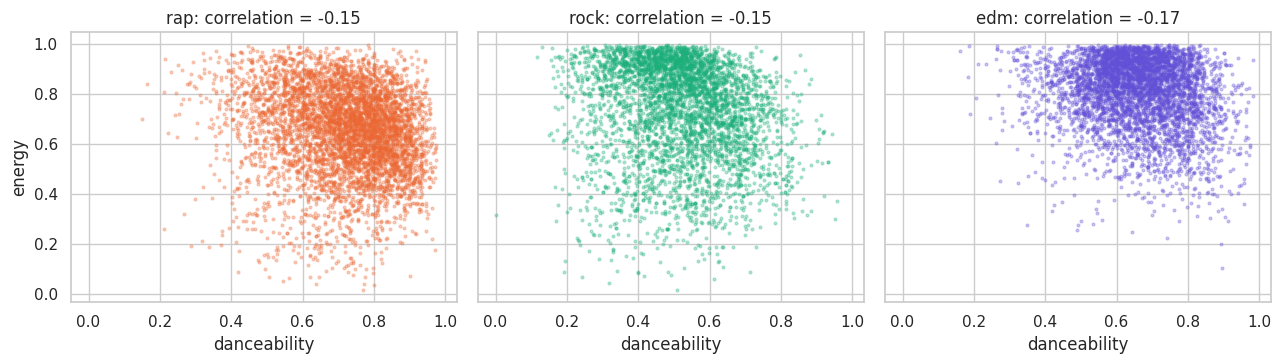

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, g in zip(axes, THREE):
    d = trio[trio["playlist_genre"] == g]
    ax.scatter(d["danceability"], d["energy"], s=4, alpha=0.3, color=GENRE_COLORS[g])
    ax.set(title=f"{g}: correlation = {d['danceability'].corr(d['energy']):.2f}", xlabel="danceability")
axes[0].set_ylabel("energy")
plt.tight_layout()
plt.show()

The correlations within each genre look small. Be careful, though: **low correlation does not prove independence**. Naive Bayes treats the features as independent within each genre to keep the math simple, and it often works well even when this is only approximately true.

### From a distribution to a likelihood

Gaussian Naive Bayes fits a **bell curve for each feature within each genre**. For a given song, the height of each curve at the song's value is the **likelihood** for that genre. This height is a probability *density*, not the probability of that exact value. The dots mark the song **"Levels" by Avicii**.

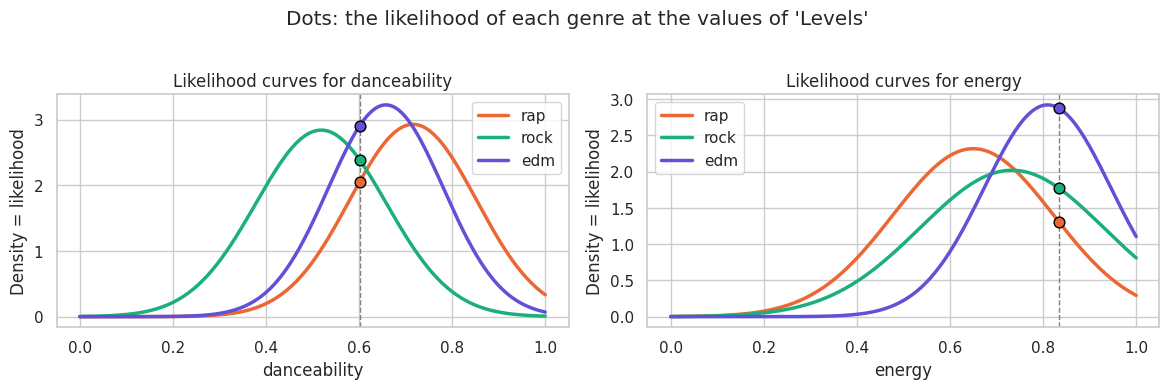

In [43]:
FEATURES_2 = ["danceability", "energy"]
means = trio.groupby("playlist_genre")[FEATURES_2].mean()
sds = trio.groupby("playlist_genre")[FEATURES_2].std(ddof=0)
levels = trio[trio["track_id"] == "6dfXwa0dI1sBm4CIePuOYM"].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
grid = np.linspace(0, 1, 300)
for ax, feat in zip(axes, FEATURES_2):
    for g in THREE:
        ax.plot(grid, stats.norm.pdf(grid, means.loc[g, feat], sds.loc[g, feat]), color=GENRE_COLORS[g], lw=2.5, label=g)
        ax.scatter(levels[feat], stats.norm.pdf(levels[feat], means.loc[g, feat], sds.loc[g, feat]),
                   color=GENRE_COLORS[g], s=60, zorder=3, edgecolor="black")
    ax.axvline(levels[feat], color="gray", ls="--", lw=1)
    ax.set(title=f"Likelihood curves for {feat}", xlabel=feat, ylabel="Density = likelihood")
    ax.legend()
plt.suptitle(f"Dots: the likelihood of each genre at the values of '{levels['track_name']}'", y=1.02)
plt.tight_layout()
plt.show()

Levels has danceability 0.60 and energy 0.83. For danceability, the EDM curve is somewhat higher than the others at that value; for energy, the EDM curve is clearly the highest. Multiplying the two heights by the prior gives each genre's score.

### Data Story 6 Classifying Three Famous Songs by Hand

We now classify three well-known songs by hand: "Levels" (Avicii, labelled edm), "Smells Like Teen Spirit" (Nirvana, labelled rock) and "God's Plan" (Drake, labelled rap). For each genre we compute prior x likelihood(danceability) x likelihood(energy).

In [44]:
def classify_by_hand(track_id):
    song = trio[trio["track_id"] == track_id].iloc[0]
    table = pd.DataFrame({"prior": priors})
    for feat in FEATURES_2:
        table[f"likelihood {feat}"] = [stats.norm.pdf(song[feat], means.loc[g, feat], sds.loc[g, feat]) for g in THREE]
    table["score"] = table.prod(axis=1)                         # prior x likelihood x likelihood
    table["posterior"] = table["score"] / table["score"].sum()
    return song, table


EXAMPLES = {"6dfXwa0dI1sBm4CIePuOYM": "Levels",
            "1f3yAtsJtY87CTmM8RLnxf": "Smells Like Teen Spirit",
            "2XW4DbS6NddZxRPm5rMCeY": "God's Plan"}

song, table = classify_by_hand("6dfXwa0dI1sBm4CIePuOYM")
print(f"{song['track_name']} by {song['track_artist']}: danceability {song['danceability']}, energy {song['energy']}")
table.round(4)

Levels by Avicii: danceability 0.601, energy 0.834


,prior,likelihood danceability,likelihood energy,score,posterior
playlist_genre,,,,,
rap,0.3702,2.0502,1.3070,0.9921,0.1970
rock,0.2953,2.3911,1.7729,1.2517,0.2485
edm,0.3345,2.9040,2.8756,2.7933,0.5545


**Naive Bayes multiplication:** each row is one candidate genre. Multiply its three numbers (the prior and the two likelihoods) to get its *score*, then divide each score by the total of all scores to get the *posterior*.

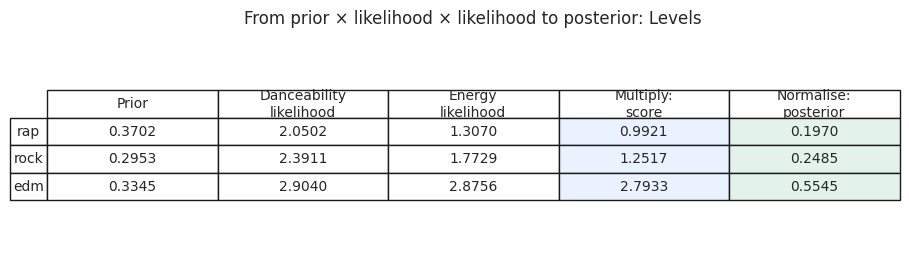

In [45]:
# Show every factor used to classify "Levels" (the first hand-worked example).
_, factor_table = classify_by_hand("6dfXwa0dI1sBm4CIePuOYM")
factors = factor_table.loc[THREE, ["prior", "likelihood danceability",
                                   "likelihood energy", "score", "posterior"]]
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.axis("off")
col_labels = ["Prior", "Danceability\nlikelihood", "Energy\nlikelihood",
              "Multiply:\nscore", "Normalise:\nposterior"]
cell = [[f"{v:.4f}" for v in factors.loc[g]] for g in THREE]
tbl = ax.table(cellText=cell, rowLabels=THREE, colLabels=col_labels,
               loc="center", cellLoc="center", rowLoc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(10); tbl.scale(1, 1.65)
for r in range(1, len(THREE)+1):
    for c in (3, 4):
        tbl[(r, c)].set_facecolor("#e3f3eb" if c == 4 else "#e9f2fe")
ax.set_title("From prior × likelihood × likelihood to posterior: Levels", pad=10)
plt.show()

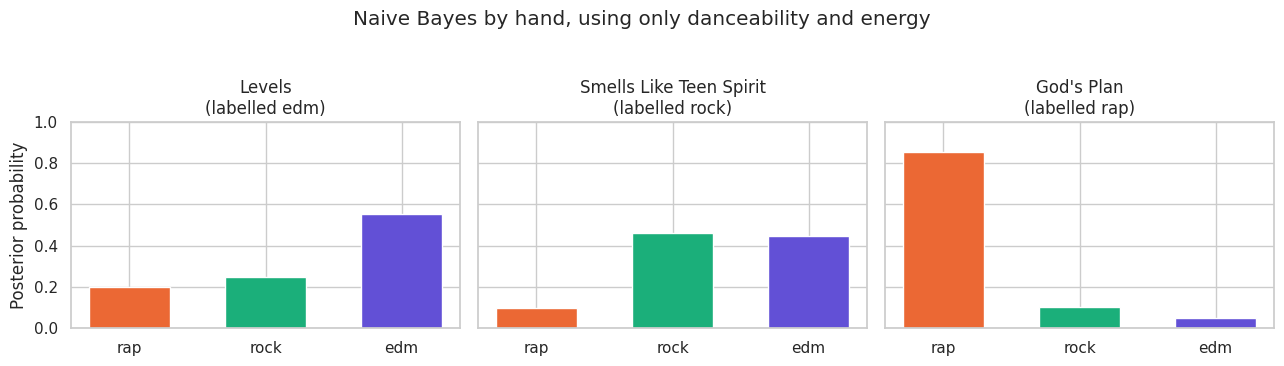

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (track_id, name) in zip(axes, EXAMPLES.items()):
    song, table = classify_by_hand(track_id)
    ax.bar(THREE, table["posterior"], color=[GENRE_COLORS[g] for g in THREE], width=0.6)
    ax.set(title=f"{name}\n(labelled {song['playlist_genre']})", ylim=(0, 1))
axes[0].set_ylabel("Posterior probability")
plt.suptitle("Naive Bayes by hand, using only danceability and energy", y=1.04)
plt.tight_layout()
plt.show()

All three songs are assigned their labelled genre, but with very different confidence. "God's Plan" is easy (0.85 for rap): high danceability and low energy are typical of rap. "Smells Like Teen Spirit" is nearly a tie between rock (0.46) and EDM (0.45): with only two features, a loud rock song looks a lot like EDM. Exercise 8 asks you to add a third feature.

scikit-learn's `GaussianNB` does the same calculation automatically. Let's check that it matches our hand calculation.

In [47]:
from sklearn.naive_bayes import GaussianNB

gnb_two = GaussianNB().fit(trio[FEATURES_2], trio["playlist_genre"])
for track_id, name in EXAMPLES.items():
    proba = gnb_two.predict_proba(trio.loc[trio["track_id"] == track_id, FEATURES_2])[0]
    hand = classify_by_hand(track_id)[1]["posterior"]
    print(f"{name:24s} sklearn: {dict(zip(gnb_two.classes_.tolist(), proba.round(3).tolist()))}"
          f"   by hand: {hand.round(3).to_dict()}")

Levels                   sklearn: {'edm': 0.555, 'rap': 0.197, 'rock': 0.248}   by hand: {'rap': 0.197, 'rock': 0.248, 'edm': 0.555}
Smells Like Teen Spirit  sklearn: {'edm': 0.445, 'rap': 0.094, 'rock': 0.461}   by hand: {'rap': 0.094, 'rock': 0.461, 'edm': 0.445}
God's Plan               sklearn: {'edm': 0.048, 'rap': 0.853, 'rock': 0.099}   by hand: {'rap': 0.853, 'rock': 0.099, 'edm': 0.048}


The results match up to rounding. `GaussianNB` learns the class priors and one bell curve for each feature and genre, then combines the densities into posterior probabilities, just as we did by hand.

### Exercise 8 Classify a Song

1. Find another song in `trio` (filter `track_name`) and run `classify_by_hand` on its `track_id`. Does the model agree with the label?
2. Add `speechiness` to `FEATURES_2`, recompute `means` and `sds`, and run the three examples again. Which posterior changes the most, and why?

In [48]:
# Your code here

## 9. Naive Bayes Variants: Gaussian, Bernoulli and Multinomial

The recipe is always the same: **prior x product of likelihoods**. Only the distribution used for each likelihood changes, depending on the type of feature.

| Variant | Feature type | Likelihood | Example here |
|---|---|---|---|
| **GaussianNB** | numbers | a bell curve per genre and feature | audio features |
| **BernoulliNB** | yes or no (1 or 0) | P(feature = 1 \| genre) | "above the median?" |
| **MultinomialNB** | counts | each word's share of the word counts in a genre | words in song titles |

### What happens when a model predicts?

All three Naive Bayes models follow the same process:

1. **`fit(...)` (learn):** find how common each genre is (the **prior**) and learn what its features usually look like (the **likelihoods**).
2. **`predict_proba(...)` (score):** for a new song, compute **prior x feature likelihoods** for each genre, then normalize the scores into **posterior probabilities**.
3. **`predict(...)` (choose):** return the genre with the highest posterior.

The three models differ in **what their inputs look like** and **how they compute a likelihood**. To compare them, we will follow **one real song from the test set** through all three models. The models never see this song during training.

### Train and test split

We train on 75% of the songs and test on the other 25%, which the model has **never seen**. The **baseline** always guesses the most common genre; a useful model must beat it.

In [49]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB, MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix

FEATURES = ["danceability", "energy", "valence", "tempo", "speechiness", "acousticness", "loudness", "minutes"]
train, test = train_test_split(trio, test_size=0.25, random_state=42, stratify=trio["playlist_genre"])
baseline = (test["playlist_genre"] == train["playlist_genre"].mode()[0]).mean()
print(f"Training songs: {len(train)}, test songs: {len(test)}, baseline accuracy: {baseline:.3f}")


def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=THREE, normalize="true")
    plt.figure(figsize=(4.5, 3.8))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=THREE, yticklabels=THREE, cbar=False)
    plt.title(title)
    plt.xlabel("Predicted genre")
    plt.ylabel("Actual genre")
    plt.show()

Training songs: 10935, test songs: 3645, baseline accuracy: 0.370


Next, we pick the test song we will follow through all three models. We choose a title that contains "remix", which will be useful later for the word-count model.

In [50]:
# Select one REAL song from the held-out test set to follow through all three models.
# A title containing "remix" is useful for the later word-count example.
candidates = test[test["track_name"].str.contains("remix", case=False, na=False)]
demo_song = (candidates if not candidates.empty else test).iloc[[0]]
print("Our test song:", demo_song.iloc[0]["track_name"])
print("Playlist label:", demo_song.iloc[0]["playlist_genre"])
print("Audio measurements:", demo_song[FEATURES].round(2).iloc[0].to_dict())

Our test song: I Would Like - R3hab Remix
Playlist label: edm
Audio measurements: {'danceability': 0.67, 'energy': 0.76, 'valence': 0.32, 'tempo': 139.94, 'speechiness': 0.06, 'acousticness': 0.07, 'loudness': -3.86, 'minutes': 2.45}


### Gaussian Naive Bayes: continuous features

**What it takes in:** real-valued audio measurements such as `energy`, `speechiness` and `tempo`.

**What `fit` learns:** for every genre and every feature, the feature's **mean** $\mu$ and **variance** $\sigma^2$. Together these define a bell curve for that feature *within that genre*.

**How it predicts:** look up the **density** (curve height) of each of the song's values under each genre's curves, multiply those densities by the genre's **prior**, then normalize the scores. In practice, the library adds logarithms instead of multiplying, because multiplying many small numbers gives values too small for the computer to store accurately.

Remember Data Story 4: the bell curve is an **approximation**, and not every audio feature has a bell shape.

Now fit the model using **eight audio features**. In the confusion matrix, each row is the actual genre and each column is the predicted genre; the diagonal shows the correct predictions.

Gaussian NB accuracy: 0.730   (baseline 0.370)


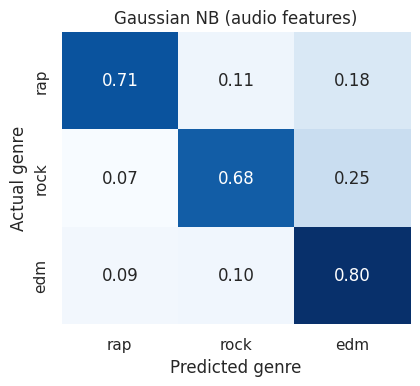

In [51]:
gnb = GaussianNB().fit(train[FEATURES], train["playlist_genre"])
pred_gnb = gnb.predict(test[FEATURES])
acc_gnb = accuracy_score(test["playlist_genre"], pred_gnb)
print(f"Gaussian NB accuracy: {acc_gnb:.3f}   (baseline {baseline:.3f})")
plot_confusion(test["playlist_genre"], pred_gnb, "Gaussian NB (audio features)")

**Follow one song through Gaussian NB.** The model has learned a different mean and SD of **energy** for each genre. The table shows how high each genre's energy curve is at our test song's energy value. The **final posterior** uses *all eight features*, not energy alone.

In [52]:
# What did GaussianNB learn about energy for each genre?
energy_idx = FEATURES.index("energy")
energy_value = float(demo_song.iloc[0]["energy"])
rows = []
posterior = gnb.predict_proba(demo_song[FEATURES])[0]
for i, genre in enumerate(gnb.classes_):
    mu = gnb.theta_[i, energy_idx]
    sd = np.sqrt(gnb.var_[i, energy_idx])
    rows.append((genre, mu, sd, stats.norm.pdf(energy_value, mu, sd), posterior[i]))
print(f"This song's energy = {energy_value:.2f}")
print("Predicted genre:", gnb.predict(demo_song[FEATURES])[0])
pd.DataFrame(rows, columns=["Genre", "Learned mean energy", "Learned SD",
                            "PDF height at song's energy", "Posterior (all 8 features)"]).set_index("Genre").loc[THREE].round(3)

This song's energy = 0.76
Predicted genre: edm


,Learned mean energy,Learned SD,PDF height at song's energy,Posterior (all 8 features)
Genre,,,,
rap,0.650,0.172,1.866,0.036
rock,0.732,0.199,1.979,0.048
edm,0.809,0.138,2.729,0.917


Gaussian NB reaches 73% accuracy, well above the 37% baseline. In the confusion matrix, EDM is recognized most often (80%). The most common mistake is rock predicted as EDM (25% of rock songs), because both genres can have high energy.

### Bernoulli Naive Bayes: yes or no features

**What it takes in:** `0`/`1` flags. For each audio feature we ask: **is this song above the training-set median?** A measurement such as `speechiness = 0.25` becomes just **yes (1)** or **no (0)**.

**What `fit` learns:** for every genre and every flag, the probability of **yes**. If a song's answer is **no**, the model uses 1 - P(yes | genre) instead. By default it also applies smoothing (explained at the end of this section).

**How it predicts:** multiply the prior by the likelihood of **every yes and every no** in the song, then normalize to get posterior probabilities. The heatmap shows the learned P(yes | genre) values.

Bernoulli NB accuracy: 0.637   (baseline 0.370)


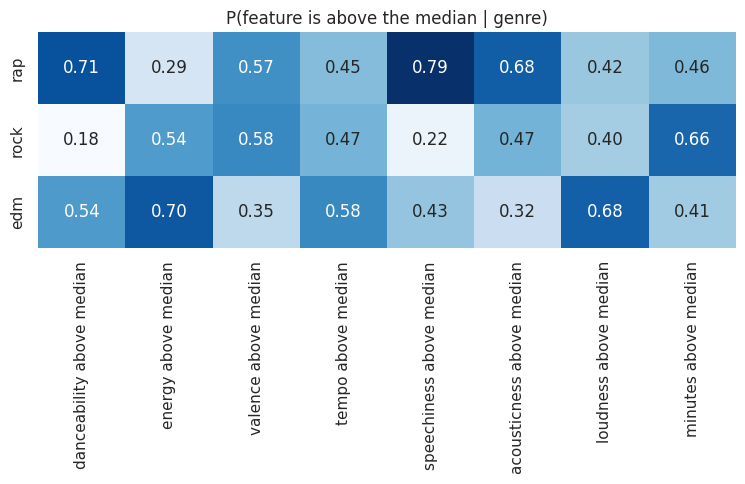

In [53]:
medians = train[FEATURES].median()                     # computed on training data only
train_yes = (train[FEATURES] > medians).astype(int)
test_yes = (test[FEATURES] > medians).astype(int)

bnb = BernoulliNB().fit(train_yes, train["playlist_genre"])
pred_bnb = bnb.predict(test_yes)
acc_bnb = accuracy_score(test["playlist_genre"], pred_bnb)
print(f"Bernoulli NB accuracy: {acc_bnb:.3f}   (baseline {baseline:.3f})")

p_yes = pd.DataFrame(np.exp(bnb.feature_log_prob_), index=bnb.classes_,
                     columns=[f"{f} above median" for f in FEATURES]).loc[THREE]
plt.figure(figsize=(9, 2.8))
sns.heatmap(p_yes, annot=True, fmt=".2f", cmap="Blues", cbar=False)
plt.title("P(feature is above the median | genre)")
plt.show()

**Follow the same song through Bernoulli NB.** First, see how the **training-set median** turns the song's audio values into yes or no answers. Then, for `speechiness`, compare the likelihood of the song's answer across genres. The final posterior uses all eight flags.

In [54]:
# These 0/1 values, not the raw numbers, are the features BernoulliNB sees.
flags = (demo_song[FEATURES] > medians).astype(int)
print("Song's inputs (1 = above the training median):")
print(pd.DataFrame({"Value": demo_song[FEATURES].iloc[0],
                    "Training median": medians, "Flag": flags.iloc[0]}).loc[
                        ["energy", "speechiness", "acousticness"]].round(3))

feature_idx = FEATURES.index("speechiness")
answer = int(flags.iloc[0]["speechiness"])
p_yes = np.exp(bnb.feature_log_prob_[:, feature_idx])
likelihood = p_yes if answer == 1 else 1 - p_yes
posterior = bnb.predict_proba(flags)[0]
print(f"For speechiness, this song's answer is {answer} (0 = no, 1 = yes).")
print("Predicted genre:", bnb.predict(flags)[0])
pd.DataFrame({"Likelihood of this answer": likelihood,
              "Posterior (all 8 flags)": posterior}, index=bnb.classes_).loc[THREE].round(3)

Song's inputs (1 = above the training median):
              Value  Training median  Flag
energy        0.763            0.756     1
speechiness   0.056            0.069     0
acousticness  0.073            0.045     1
For speechiness, this song's answer is 0 (0 = no, 1 = yes).
Predicted genre: edm


,Likelihood of this answer,Posterior (all 8 flags)
rap,0.210,0.113
rock,0.781,0.066
edm,0.573,0.821


For example, about 8 in 10 rap songs are above the median for speechiness. Bernoulli NB scores 64%, below Gaussian NB's 73%, because yes or no answers throw away detail. It is the natural choice when the data really **is** yes or no, such as whether a word appears in a text.

### Multinomial Naive Bayes: word counts

**What it takes in:** **word counts** from each song title, made with `CountVectorizer`, not audio measurements. This is a classic text classifier. Each title becomes a **bag of words**: word order is ignored, but a repeated word counts more than once.

**What it learns:** `CountVectorizer` learns the vocabulary (the list of words) from the training titles. `MultinomialNB.fit` then learns how often each word appears in each genre's titles, using smoothing so that no word gets a probability of exactly zero.

**How it predicts:** for each genre, combine the prior with the likelihood of every word in the title, then normalize across genres to get the posterior. Note that this model learns **patterns in track titles**, not the sound of the songs.

### Data Story 7 What Song Titles Reveal

Can a model guess a song's genre from its **title alone**? First, look at how `CountVectorizer` turns three real training-set titles (chosen because they contain the words "remix", "live" and "feat") into word counts.

In [55]:
from sklearn.feature_extraction.text import CountVectorizer

# Choose three REAL training-set titles, with different words to count.
examples = []
for keyword in ["remix", "live", "feat"]:
    matches = train.loc[train["track_name"].str.contains(keyword, case=False, na=False), "track_name"]
    if not matches.empty:
        examples.append(matches.iloc[0])
demo = CountVectorizer()
pd.DataFrame(demo.fit_transform(examples).toarray(),
             index=examples, columns=demo.get_feature_names_out())

,feat,giving,jaden,krischvn,lil,live,michaels,remix,reply,the,to,up,uzi,vert,will
Giving Up (feat. Jaden Michaels) - Krischvn Remix,1,1,1,1,0,0,1,1,0,0,0,1,0,0,0
The Will To Live,0,0,0,0,0,1,0,0,0,1,1,0,0,0,1
Reply (feat. Lil Uzi Vert),1,0,0,0,1,0,0,0,1,0,0,0,1,1,0


Vocabulary: 8425 words
Multinomial NB accuracy from titles alone: 0.631   (baseline 0.370)


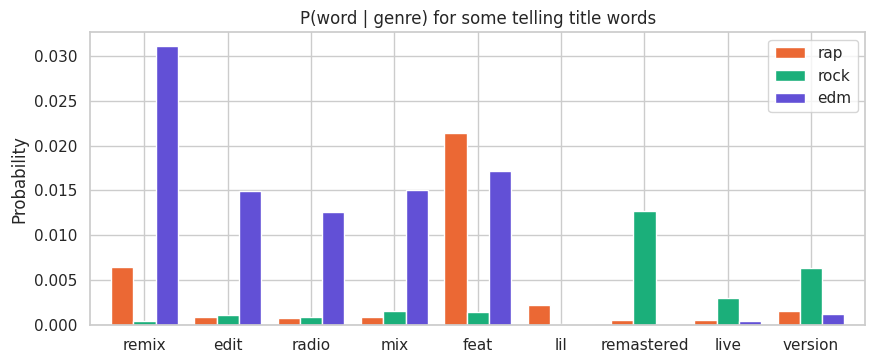

In [56]:
vectorizer = CountVectorizer()
X_train = vectorizer.fit_transform(train["track_name"])        # learn the vocabulary on training titles only
X_test = vectorizer.transform(test["track_name"])

mnb = MultinomialNB().fit(X_train, train["playlist_genre"])
pred_mnb = mnb.predict(X_test)
acc_mnb = accuracy_score(test["playlist_genre"], pred_mnb)
print(f"Vocabulary: {len(vectorizer.vocabulary_)} words")
print(f"Multinomial NB accuracy from titles alone: {acc_mnb:.3f}   (baseline {baseline:.3f})")

WORDS = ["remix", "edit", "radio", "mix", "feat", "lil", "remastered", "live", "version"]
word_probs = pd.DataFrame(np.exp(mnb.feature_log_prob_).T, index=vectorizer.get_feature_names_out(),
                          columns=mnb.classes_).loc[WORDS, THREE]
ax = word_probs.plot(kind="bar", figsize=(10, 3.8), color=[GENRE_COLORS[g] for g in THREE], width=0.8)
ax.set(title="P(word | genre) for some telling title words", ylabel="Probability", xlabel="")
plt.xticks(rotation=0)
plt.show()

**Follow the same song through Multinomial NB.** `CountVectorizer` finds the words in its title. The model has learned a different P(word | genre) for each genre. The likelihood of one word is only part of the score: the **final posterior** uses every recognized word in the title, plus the prior.

In [57]:
# See the word counts of the same test song used above.
title_counts = vectorizer.transform(demo_song["track_name"])
known_words = pd.Series(title_counts.data,
                        index=vectorizer.get_feature_names_out()[title_counts.indices])
print("Title:", demo_song.iloc[0]["track_name"])
print("Words the trained vocabulary recognises:", known_words.to_dict())

# Show what one observed word tells the model about the three genres.
if len(known_words):
    focus = "remix" if "remix" in known_words.index else known_words.index[0]
    word_idx = vectorizer.vocabulary_[focus]
    token_likelihood = np.exp(mnb.feature_log_prob_[:, word_idx])
    print(f"Genre-specific probability of the word token '{focus}':")
    print(pd.Series(token_likelihood, index=mnb.classes_).loc[THREE].round(4))
else:
    print("No title words were in the training vocabulary; prediction uses priors.")
print("Prediction from all recognised words:", mnb.predict(title_counts)[0])
print("Posterior:", pd.Series(mnb.predict_proba(title_counts)[0],
                               index=mnb.classes_).loc[THREE].round(3).to_dict())

Title: I Would Like - R3hab Remix
Words the trained vocabulary recognises: {'like': 1, 'r3hab': 1, 'remix': 1, 'would': 1}
Genre-specific probability of the word token 'remix':
rap     0.0065
rock    0.0004
edm     0.0311
dtype: float64
Prediction from all recognised words: edm
Posterior: {'rap': 0.003, 'rock': 0.0, 'edm': 0.997}


Titles alone reach 63% accuracy, well above the baseline. EDM titles are full of **remix**, **edit**, **radio** and **mix** (as in "Radio Edit" and "Original Mix"). **feat** is common in both rap and EDM titles, while **lil** appears almost only in rap. Rock titles often contain **remastered**, **live** and **version**, from re-released classics.

So the model learns **how each genre names its releases**, not anything about the music itself.

### Smoothing: the word the model has never seen

If a word never appears in a genre's training titles, its estimated probability for that genre is 0. Naive Bayes **multiplies** probabilities, so that single zero makes the whole genre score 0. **Laplace smoothing** fixes this by adding a small count, `alpha` (default 1), to every word in every genre, so no probability is exactly 0.

Times 'remastered' appears in training titles: {'edm': 0, 'rap': 9, 'rock': 239}


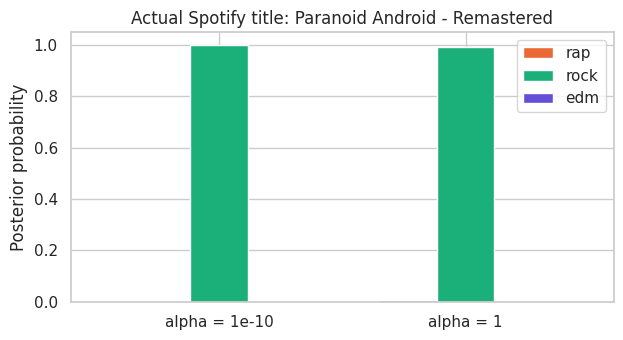

,rap,rock,edm
alpha = 1e-10,0.000,1.000,0.000
alpha = 1,0.007,0.992,0.001


In [58]:
column = X_train[:, vectorizer.vocabulary_["remastered"]].toarray().ravel()
print("Times 'remastered' appears in training titles:",
      pd.Series(column).groupby(train["playlist_genre"].to_numpy()).sum().to_dict())

# Choose a REAL test title containing the diagnostic word "remastered".
remastered_titles = test.loc[test["track_name"].str.contains("remastered", case=False, na=False), "track_name"]
example_title = remastered_titles.iloc[0] if len(remastered_titles) else test["track_name"].iloc[0]
phrase = vectorizer.transform([example_title])
results = {}
for alpha in [1e-10, 1.0]:
    model = MultinomialNB(alpha=alpha, force_alpha=True).fit(X_train, train["playlist_genre"])
    results[f"alpha = {alpha:g}"] = pd.Series(model.predict_proba(phrase)[0], index=model.classes_)[THREE]

ax = pd.DataFrame(results).T.plot(kind="bar", figsize=(7, 3.5), color=[GENRE_COLORS[g] for g in THREE], width=0.7)
ax.set(title=f"Actual Spotify title: {example_title[:64]}", ylabel="Posterior probability", xlabel="")
plt.xticks(rotation=0)
plt.show()
pd.DataFrame(results).T.round(3)

In the training set, the word **remastered** never appears in an EDM title. With almost no smoothing (alpha = 1e-10), seeing that word rules out EDM completely. With Laplace smoothing (alpha = 1), EDM stays possible, so the other words in the title can still count.

### Summary of the three variants

The chart compares the test accuracy of the three models with the baseline.

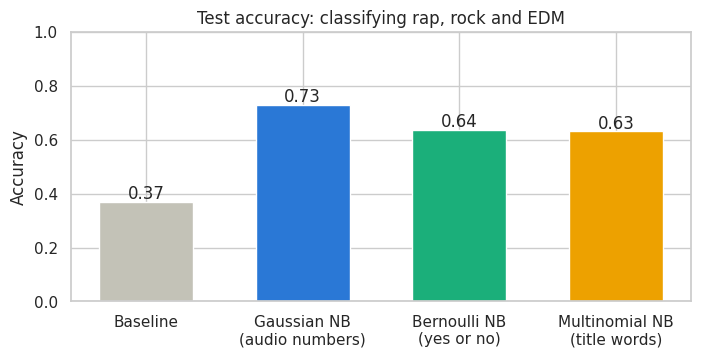

In [59]:
results = pd.Series({"Baseline": baseline, "Gaussian NB\n(audio numbers)": acc_gnb,
                     "Bernoulli NB\n(yes or no)": acc_bnb, "Multinomial NB\n(title words)": acc_mnb})
plt.figure(figsize=(8, 3.5))
plt.bar(results.index, results.values, color=[GRAY, "#2a78d6", "#1baf7a", "#eda100"], width=0.6)
for i, v in enumerate(results.values):
    plt.text(i, v + 0.01, f"{v:.2f}", ha="center")
plt.title("Test accuracy: classifying rap, rock and EDM")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

### One test song, three ways of looking at it

The same song can get different predictions because each model sees different information: **Gaussian NB** sees detailed audio measurements, **Bernoulli NB** sees only above-or-below-median flags, and **Multinomial NB** sees only the words in the title. Each row below shows one model's posterior probabilities.

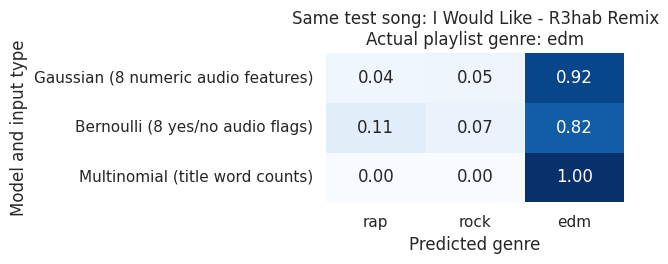

Predicted classes: {'Gaussian (8 numeric audio features)': 'edm', 'Bernoulli (8 yes/no audio flags)': 'edm', 'Multinomial (title word counts)': 'edm'}


In [60]:
# Compare all three models on EXACTLY the same held-out song.
model_posteriors = pd.DataFrame({
    "Gaussian (8 numeric audio features)": pd.Series(
        gnb.predict_proba(demo_song[FEATURES])[0], index=gnb.classes_),
    "Bernoulli (8 yes/no audio flags)": pd.Series(
        bnb.predict_proba((demo_song[FEATURES] > medians).astype(int))[0], index=bnb.classes_),
    "Multinomial (title word counts)": pd.Series(
        mnb.predict_proba(vectorizer.transform(demo_song["track_name"]))[0], index=mnb.classes_)
}).T[THREE]

plt.figure(figsize=(6.5, 2.8))
sns.heatmap(model_posteriors, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False)
plt.title(f"Same test song: {demo_song.iloc[0]['track_name'][:45]}\nActual playlist genre: {demo_song.iloc[0]['playlist_genre']}")
plt.xlabel("Predicted genre")
plt.ylabel("Model and input type")
plt.tight_layout()
plt.show()
print("Predicted classes:", model_posteriors.idxmax(axis=1).to_dict())

### Exercise 9 Your Own Classifier

1. Repeat the Gaussian NB analysis with **all six genres** (use `songs` instead of `trio`). What is the new baseline, and how does the accuracy change? Plot the confusion matrix and name the two genres the model confuses most often.
2. Use Multinomial NB on titles, but only for test songs whose titles contain at least one of the words in `WORDS` (the words in the chart in Data Story 7). Is the model more accurate on those songs? Why?

In [61]:
# Your code here

## Summary

| Topic | Key idea | Spotify example |
|---|---|---|
| Probability | times an event happened divided by all trials | P(genre) |
| Rules | complement, addition, subtract the overlap | rap and very danceable Venn diagram |
| Conditional probability | restrict to the given group | genre among very danceable songs |
| Independence | $P(A \mid B)=P(A)$ | mode vs. genre |
| Random variables | discrete counts or continuous measurements | songs in C (X), average tempo (T) |
| PMF vs. PDF | bar heights vs. areas under a curve | popularity (PMF), tempo (PDF) |
| Bernoulli, Binomial, Multinomial | one yes or no, count of yeses, counts by category | major-key songs, genre shuffles |
| Normal distribution | bell curve, z-scores, the 68-95-99.7 rule | valence and song length |
| Bayes' theorem | posterior = likelihood x prior / evidence | high energy and EDM |
| Naive Bayes | multiply the per-feature likelihoods | three songs classified by hand |
| Variants | Gaussian for numbers, Bernoulli for yes or no flags, Multinomial for counts | audio features, median flags, title words |